# Supplementary figures

In [1]:
import re, logging, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator, MultipleLocator
import seaborn as sns
from scipy import stats
from sklearn.metrics import (roc_curve, roc_auc_score, auc, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, accuracy_score)
from sklearn.preprocessing import label_binarize
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test
from IPython.display import display

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

DATA = Path("source_data")
SD = DATA / "Supplementary_Figure"
OUT = Path("outputs/supplementary")
OUT.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 200)

Z975 = stats.norm.ppf(0.975)
SANS = ["Arial", "Liberation Sans", "Helvetica", "DejaVu Sans"]

def reset_style(**rc):
    mpl.rcdefaults()
    plt.rcParams.update({"figure.dpi": 100, "savefig.facecolor": "white", "pdf.fonttype": 42})
    plt.rcParams.update(rc)

def save(fig, name, dpi=300):
    fig.savefig(OUT / f"{name}.png", dpi=dpi, bbox_inches="tight", facecolor="white")
    fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight", facecolor="white")
    plt.show()

def macro_interp_auc(Y, P):
    fprs, tprs = [], []
    for j in range(Y.shape[1]):
        f, t, _ = roc_curve(Y[:, j], P[:, j]); fprs.append(f); tprs.append(t)
    all_f = np.unique(np.concatenate(fprs))
    mean_t = np.mean([np.interp(all_f, f, t) for f, t in zip(fprs, tprs)], axis=0)
    return auc(all_f, mean_t)

def ovr_aucs(truth_idx, P, classes, macro=False):
    truth_idx = np.asarray(truth_idx); P = np.asarray(P, float)
    point = [roc_auc_score(truth_idx == j, P[:, j]) for j in classes]
    if macro:
        point.append(macro_interp_auc(np.column_stack([truth_idx == j for j in classes]).astype(int), P[:, classes]))
    return np.array(point)

def youden(y, s):
    fpr, tpr, thr = roc_curve(y, s)
    i = int(np.argmax(tpr - fpr))
    return thr[i], fpr[i], tpr[i], fpr, tpr, i

def pearson_fisher(x, y):
    x = np.asarray(x, float); y = np.asarray(y, float)
    r, p = stats.pearsonr(x, y); n = x.size
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    return dict(n=n, df=n - 2, r=r, ci_low=np.tanh(z - Z975 * se), ci_high=np.tanh(z + Z975 * se), p=p)

ci3 = lambda lo, hi: f"[{lo:.3f}, {hi:.3f}]"

## Supplementary Fig 1

rows = 200, devices = 5, tasks = 4, runs per device-task = [10]


Task,ViT,Mitosis,MIB-YOLO,MIB-Cellpose SAM
Device,,,,
M4 Pro,26 ms,70 ms,3.5 s,1.1 s
Mac M3,37 ms,91 ms,6.4 s,2.5 s
Mac M2,42 ms,151 ms,7.3 s,4.7 s
Mac M1,71 ms,347 ms,9.1 s,5.4 s
Mac Intel,298 ms,843 ms,11.5 s,38.7 s


,ViT,Mitosis,MIB-YOLO,MIB-Cellpose SAM
Device,,,,
M4 Pro,2.5,9.4,247.7,24.5
Mac M3,4.5,7.2,352.9,94.9
Mac M2,5.1,40.1,321.0,129.7
Mac M1,6.5,47.6,691.4,271.7
Mac Intel,20.1,38.3,1303.1,2039.2


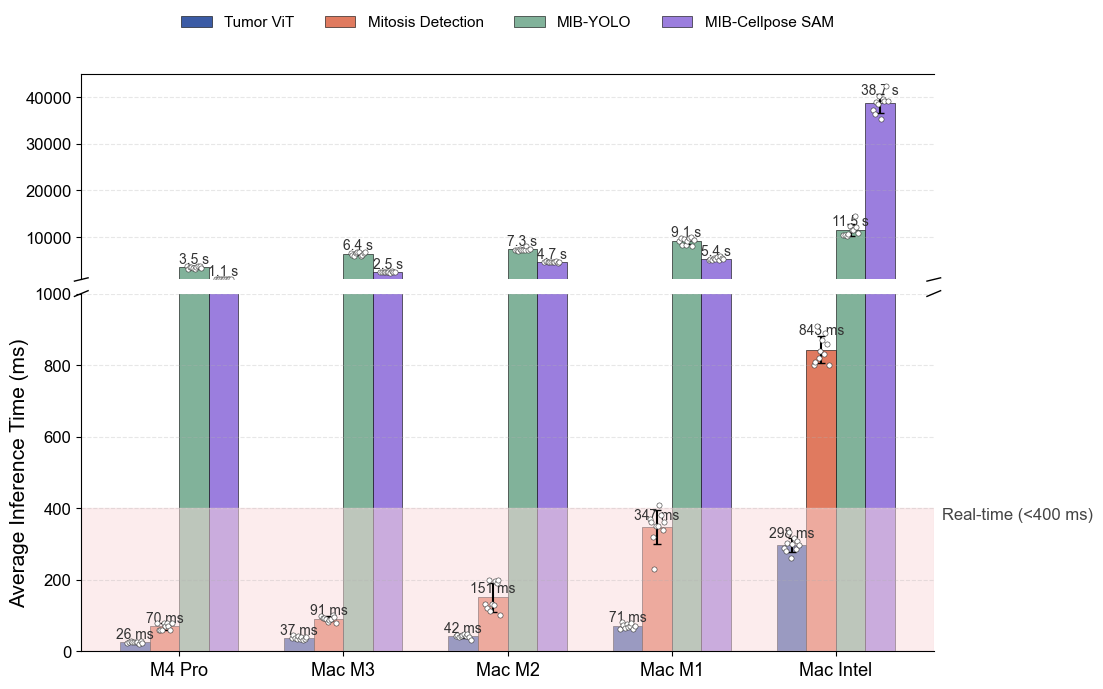

In [2]:
reset_style(**{"font.family": "sans-serif", "font.sans-serif": SANS, "font.size": 15, "axes.labelsize": 15,
               "axes.titlesize": 16, "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12})

df = pd.read_csv(SD / "fig1" / "macOS_inference_times.csv")
df["Time (ms)"] = df["Time (s)"] * 1000
device_order = ["M4 Pro", "Mac M3", "Mac M2", "Mac M1", "Mac Intel"]
task_order = ["ViT", "Mitosis", "MIB-YOLO", "MIB-Cellpose SAM"]
summary = df.groupby(["Device", "Task"])["Time (ms)"].agg(["count", "mean", "std"]).reset_index()

def bar_label(task, v):
    return f"{v:.0f} ms" if task in ("ViT", "Mitosis") else f"{v / 1000:.1f} s"

tab = summary.assign(label=[bar_label(t, v) for t, v in zip(summary.Task, summary["mean"])])
print(f"rows = {len(df)}, devices = {df.Device.nunique()}, tasks = {df.Task.nunique()}, "
      f"runs per device-task = {sorted(summary['count'].unique())}")
display(tab.pivot(index="Device", columns="Task", values="label").reindex(index=device_order, columns=task_order))
display(summary.assign(mean_ms=summary["mean"].round(1), sd_ms=summary["std"].round(1))
        .pivot(index="Device", columns="Task", values="sd_ms").reindex(index=device_order, columns=task_order)
        .rename_axis(None, axis=1).style.format("{:.1f}").set_caption("SD (ms)"))

colors = {"ViT": "#3B5BA5", "Mitosis": "#E07A5F", "MIB-YOLO": "#81B29A", "MIB-Cellpose SAM": "#9B7EDE"}

def add_labels(ax, bars, values, unit="ms", y_scale=1.03):
    for bar, val in zip(bars, values):
        height = bar.get_height()
        if np.isnan(height):
            continue
        text = f"{val:.0f} ms" if unit == "ms" else f"{val:.1f} s"
        ax.text(bar.get_x() + bar.get_width() / 2, height * y_scale, text,
                ha="center", va="bottom", fontsize=10, color="#333333")

x = np.arange(len(device_order)); width = 0.18
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, sharex=True, figsize=(11, 7.5),
                                        gridspec_kw={"height_ratios": [1.15, 2], "hspace": 0.05})
for i, task in enumerate(task_order):
    ts = summary[summary["Task"] == task].set_index("Device").reindex(device_order).reset_index()
    positions = x + (i - 1.5) * width
    axes_to_plot = [ax_bottom] + ([ax_top] if task in ["MIB-YOLO", "MIB-Cellpose SAM"] else [])
    for ax in axes_to_plot:
        bars = ax.bar(positions, ts["mean"], width, yerr=ts["std"], capsize=3, label=task,
                      color=colors[task], edgecolor="black", linewidth=0.4)
        show_points = ((ax is ax_bottom and task in ["ViT", "Mitosis"]) or
                       (ax is ax_top and task in ["MIB-YOLO", "MIB-Cellpose SAM"]))
        if show_points:
            for j, device in enumerate(device_order):
                values = df[(df["Device"] == device) & (df["Task"] == task)]["Time (ms)"].to_numpy()
                offsets = np.linspace(-width * 0.25, width * 0.25, len(values))
                ax.scatter(positions[j] + offsets, values, s=14, facecolor="white",
                           edgecolor="#333333", linewidth=0.4, zorder=4)
        if ax is ax_bottom and task in ["ViT", "Mitosis"]:
            add_labels(ax, bars, ts["mean"], unit="ms", y_scale=1.04)
        if ax is ax_top and task in ["MIB-YOLO", "MIB-Cellpose SAM"]:
            add_labels(ax, bars, ts["mean"] / 1000, unit="s", y_scale=1.03)

ax_bottom.set_ylim(0, 1000)
ax_top.set_ylim(900, 45000)
ax_bottom.axhspan(0, 400, color="#FADADD", alpha=0.5)
ax_bottom.text(1.01, 0.38, "Real-time (<400 ms)", transform=ax_bottom.transAxes, fontsize=12,
               color="#444444", ha="left", va="center")
ax_top.spines["bottom"].set_visible(False); ax_bottom.spines["top"].set_visible(False)
ax_top.tick_params(labeltop=False, bottom=False); ax_bottom.xaxis.tick_bottom()
d = 0.008
kw = dict(transform=ax_top.transAxes, color="black", clip_on=False, linewidth=1)
ax_top.plot((-d, +d), (-d, +d), **kw); ax_top.plot((1 - d, 1 + d), (-d, +d), **kw)
kw.update(transform=ax_bottom.transAxes)
ax_bottom.plot((-d, +d), (1 - d, 1 + d), **kw); ax_bottom.plot((1 - d, 1 + d), (1 - d, 1 + d), **kw)
ax_bottom.set_xticks(x); ax_bottom.set_xticklabels(device_order, fontsize=13)
ax_bottom.set_ylabel("Average Inference Time (ms)", fontsize=15)
for ax in [ax_top, ax_bottom]:
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
handles, labels = ax_bottom.get_legend_handles_labels()
unique = dict(zip(labels, handles))
display_labels = {"ViT": "Tumor ViT", "Mitosis": "Mitosis Detection", "MIB-YOLO": "MIB-YOLO",
                  "MIB-Cellpose SAM": "MIB-Cellpose SAM"}
ax_top.legend(unique.values(), [display_labels[l] for l in unique.keys()], bbox_to_anchor=(0.5, 1.35),
              loc="upper center", ncol=4, frameon=False, fontsize=11)
save(fig, "SF1_macOS_inference_times")

## Supplementary Fig 2

machines = 25; modules/rows = 14
machines per platform build: {'Windows — GPU': 16, 'Windows — CPU': 2, 'macOS — AS': 6, 'macOS — Intel': 1}
machines on which both distributions (standard and pre-loaded) were tested: 15/25


,module,works,tested,coverage_pct
0,Brain Tumor Classifier (ViT),25,25,100.0
1,MIB — Ki-67 (YOLO),25,25,100.0
2,MIB — Ki-67 (Cellpose-SAM),25,25,100.0
3,Single-cell Phenotyping (Cellpose-SAM),25,25,100.0
4,PanNuke (CellViT-SAM-H),24,24,100.0
5,Mitosis Detection (RetinaNet),25,25,100.0
6,Magnification Detector,25,25,100.0
7,ROI Detection — Color Deconvolution,25,25,100.0
8,ROI Detection — Image-patch Clustering,25,25,100.0
9,Calibration Function,25,25,100.0


standard version blocked by Smart App Control: ['RTX5070Ti(MSI)  (12 GB)', 'RTX5080(ROG)  (16 GB)']
VLM failed to load (VRAM): ['GTX1050TI(MSI)  (4 GB)', 'GTX1080Ti(Alienware)  (11 GB)', 'i5-9400F (Gigabyte)', 'Xeon Platinum (Amazon EC2 t3)'] | VRAM (GB) of GPUs on which the VLM ran: [8, 12, 16, 20, 32]


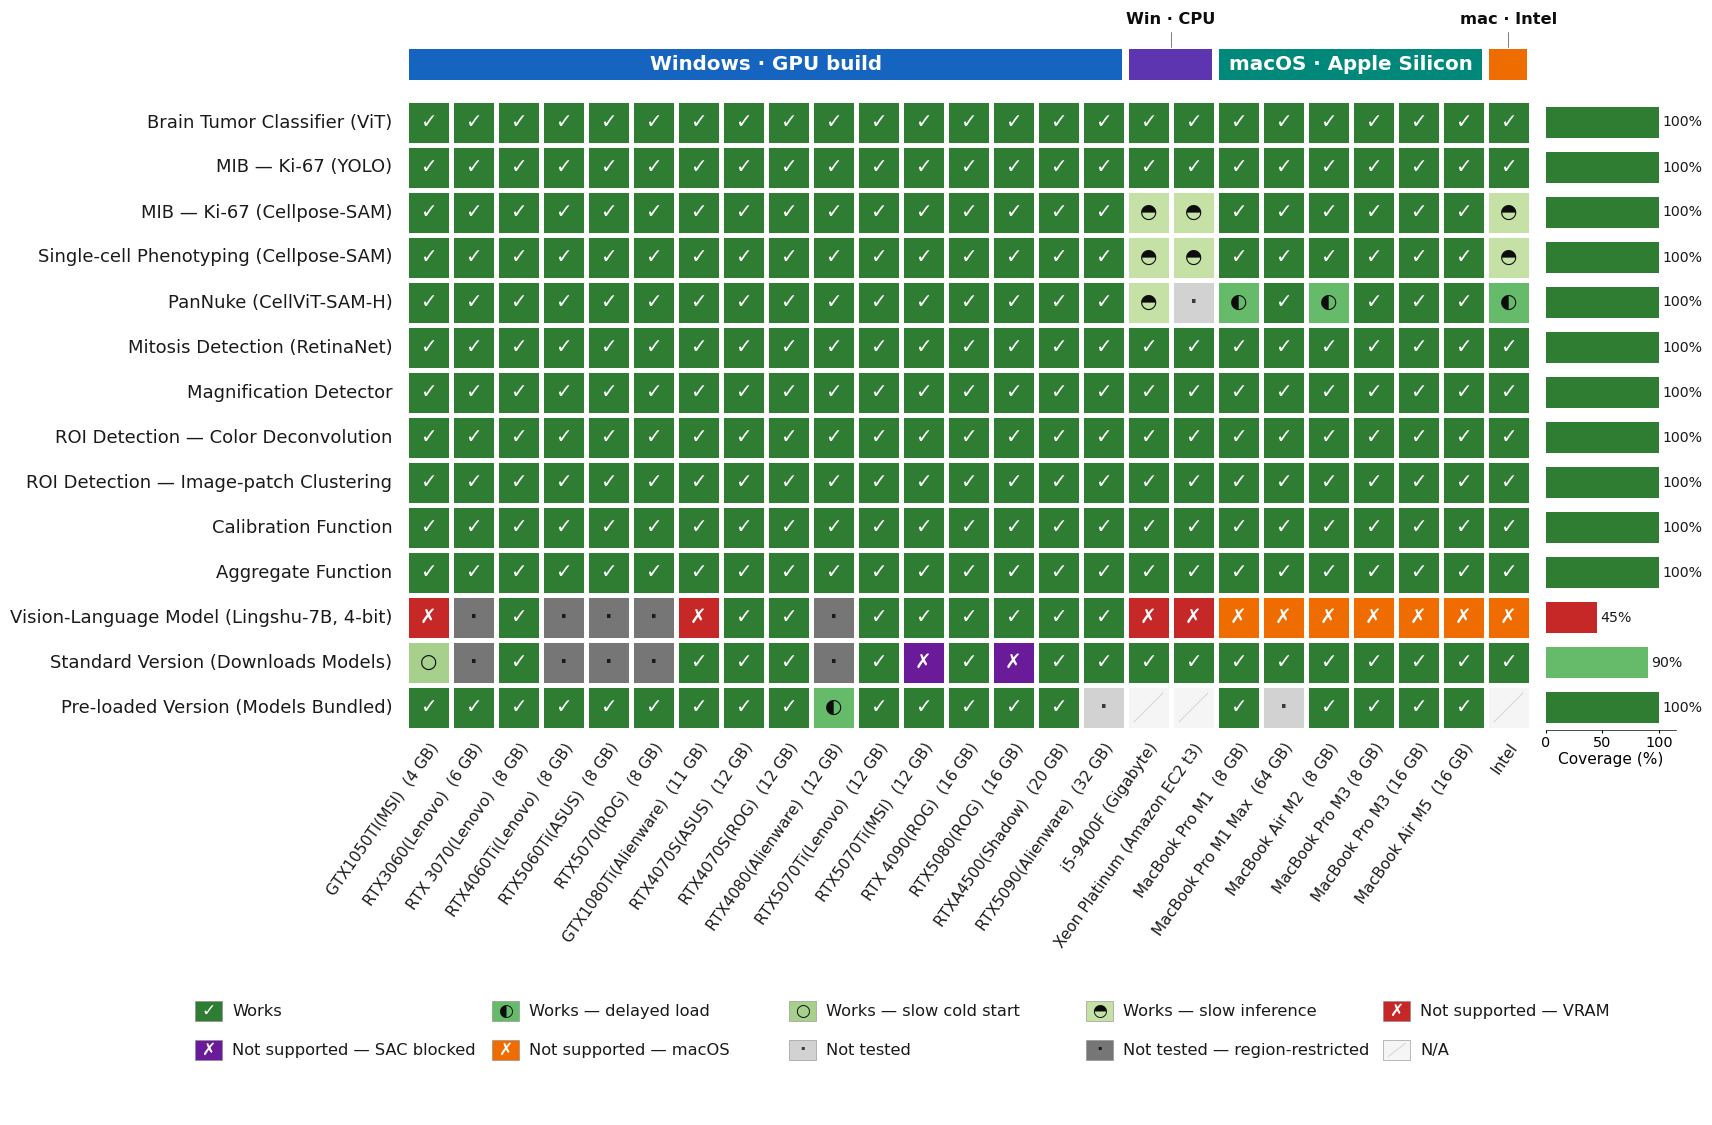

In [3]:
INPUT_XLSX = SD / "fig2" / "OnSight_Compatibility_Matrix.xlsx"
CELL_W = CELL_H = 0.45
M_LEFT, W_ROW_LABELS, W_GAP_HM_RIGHT, W_ROW_COVERAGE, M_RIGHT = 0.50, 4.30, 0.15, 1.30, 0.55
M_TOP, H_TITLE_BLOCK, H_GAP_TITLE, H_PLAT_BAND, H_GAP_BAND = 0.40, 0.00, 0.00, 0.78, 0.12
H_COL_LABELS, H_GAP_LEGEND, H_LEGEND, M_BOTTOM = 2.00, 0.55, 1.30, 0.40
FS_SCALE = 1.3
fs = lambda base: base * FS_SCALE

STATUS_STYLE = {
    "Works":            ("Works",                                         "#2E7D32", "\u2713", "white"),
    "Works_delay":      ("Works (delayed model load)",                    "#66BB6A", "\u25D0", "#0D0D0D"),
    "Works_coldstart":  ("Works (slow cold start)",                       "#A8D08D", "\u25CB", "#0D0D0D"),
    "Works_slowinf":    ("Works (slow inference)",                        "#C5E1A5", "\u25D3", "#0D0D0D"),
    "NS_VRAM":          ("Not supported \u2014 VRAM",                     "#C62828", "\u2717", "white"),
    "NS_SAC":           ("Not supported \u2014 Blocked by Smart App Control", "#6A1B9A", "\u2717", "white"),
    "NS_macOS":         ("Not supported \u2014 macOS",                    "#EF6C00", "\u2717", "white"),
    "NotTested":        ("Not tested",                                    "#D2D2D2", "\u00B7", "#3A3A3A"),
    "NotTested_Region": ("Not tested \u2014 region-restricted",           "#777676", "\u00B7", "#1A1A1A"),
    "NA":               ("N/A",                                           "#F5F5F5", "",  "#9A9A9A"),
}
SHORT_LABELS = {"Works": "Works", "Works_delay": "Works \u2014 delayed load", "Works_coldstart": "Works \u2014 slow cold start",
                "Works_slowinf": "Works \u2014 slow inference", "NS_VRAM": "Not supported \u2014 VRAM",
                "NS_SAC": "Not supported \u2014 SAC blocked", "NS_macOS": "Not supported \u2014 macOS",
                "NotTested": "Not tested", "NotTested_Region": "Not tested \u2014 region-restricted", "NA": "N/A"}
PLATFORM_COLORS = {"Windows \u2014 GPU": "#1565C0", "Windows \u2014 CPU": "#5E35B1",
                   "macOS \u2014 AS": "#00897B", "macOS \u2014 Intel": "#EF6C00"}
PLATFORM_LABELS = {"Windows \u2014 GPU": ("Windows \u00B7 GPU build", "Win \u00B7 GPU"),
                   "Windows \u2014 CPU": ("Windows \u00B7 CPU build", "Win \u00B7 CPU"),
                   "macOS \u2014 AS": ("macOS \u00B7 Apple Silicon", "mac \u00B7 AS"),
                   "macOS \u2014 Intel": ("macOS \u00B7 Intel", "mac \u00B7 Intel")}
PLATFORM_ORDER = ["Windows \u2014 GPU", "Windows \u2014 CPU", "macOS \u2014 AS", "macOS \u2014 Intel"]
GPU_VRAM = {"1050TI": 4, "3070": 8, "5070": 8, "5060TI": 8, "4060TI": 8, "3060": 6, "1080TI": 11,
            "5070TI": 12, "4070S": 12, "4080": 12, "4090": 16, "5080": 16, "A4500": 20, "5090": 32}

reset_style(**{"font.family": "DejaVu Sans", "axes.linewidth": 0.6})

raw_cm = pd.read_excel(INPUT_XLSX, sheet_name="Compatibility Matrix", header=None)
raw_mach = pd.read_excel(INPUT_XLSX, sheet_name="Machines", header=1)
machine_names = raw_cm.iloc[3, 2:].reset_index(drop=True)
mod_col = raw_cm.iloc[4:, 0].reset_index(drop=True)
data = raw_cm.iloc[4:, 2:].reset_index(drop=True); data.columns = range(data.shape[1])
keep_rows = [i for i, m in enumerate(mod_col) if pd.notna(m) and str(m).strip()]
mod_col = mod_col.iloc[keep_rows].reset_index(drop=True); data = data.iloc[keep_rows, :].reset_index(drop=True)

plat_lookup, vram_lookup, cpu_lookup = {}, {}, {}
section = None
for _, row in raw_mach.iterrows():
    sec = row.get("Section")
    if pd.notna(sec): section = str(sec).strip()
    model, cpu, vram = row.get("Model / Make"), row.get("CPU"), row.get("VRAM (GB)")
    if pd.isna(model) or section is None: continue
    model_s = str(model).strip()
    key = ("Windows \u2014 GPU" if "GPU" in section else "Windows \u2014 CPU" if "CPU" in section
           else "macOS \u2014 AS" if "Apple" in section else "macOS \u2014 Intel" if "Intel" in section else section)
    plat_lookup[model_s] = key
    if pd.notna(vram):
        try: vram_lookup.setdefault(model_s, []).append(float(str(vram).upper().replace("GB", "").strip()))
        except ValueError: pass
    if pd.notna(cpu): cpu_lookup[model_s] = str(cpu).strip()

_vram_idx = {}
def pop_vram(name):
    lst = vram_lookup.get(name, [])
    if not lst: return None
    idx = _vram_idx.get(name, 0); _vram_idx[name] = idx + 1
    return lst[idx] if idx < len(lst) else lst[-1]

def shorten_cpu(cpu_str):
    if not cpu_str: return None
    s = re.sub(r"\(R\)|\(TM\)", "", str(cpu_str).strip(), flags=re.I)
    s = re.sub(r"\s+", " ", s)
    for pat in [r"^\d+th\s+Gen\s+", r"^Intel\s+Core\s+", r"^Intel\s+", r"^AMD\s+"]:
        s = re.sub(pat, "", s, flags=re.I)
    return s.strip()

def cpu_for_display(disp_name):
    s = str(disp_name).strip()
    for k, v in plat_lookup.items():
        if v == "Windows \u2014 CPU" and (s == k or str(k).startswith(s) or s.startswith(str(k))):
            return shorten_cpu(cpu_lookup.get(k))
    return None

def resolve_machine(disp_name):
    if pd.isna(disp_name): return None, None, None
    s = str(disp_name).strip()
    if "fill in" in s.lower(): return None, None, None
    if s.startswith("MacBook"):
        for k, v in plat_lookup.items():
            if k == s: return s, v, pop_vram(k)
        return s, "macOS \u2014 AS", pop_vram(s)
    if s == "Intel" or ("Intel" == s.split()[0] and "MacBook" not in s):
        for k, v in plat_lookup.items():
            if v == "macOS \u2014 Intel" and pd.notna(k): return k, v, pop_vram(k)
        return s, "macOS \u2014 Intel", None
    m = re.search(r"(?:RTX|GTX)\s*([0-9A-Za-z]+)", s, re.IGNORECASE)
    if m: return s, "Windows \u2014 GPU", GPU_VRAM.get(m.group(1).upper())
    for k, v in plat_lookup.items():
        if v == "Windows \u2014 CPU" and (s == k or str(k).startswith(s) or s.startswith(str(k))):
            return k, v, None
    return s, "Windows \u2014 CPU", None

resolved = [resolve_machine(n) for n in machine_names]
keep_cols = [i for i, (n, p, v) in enumerate(resolved) if n is not None]
machine_names = machine_names.iloc[keep_cols].reset_index(drop=True)
data = data.iloc[:, keep_cols].reset_index(drop=True); data.columns = range(data.shape[1])
resolved = [resolved[i] for i in keep_cols]

def classify(v):
    if pd.isna(v): return "NA"
    s = str(v).strip(); sl = s.lower()
    if s == "" or sl == "nan": return "NA"
    if sl.startswith("works"):
        if "cold start" in sl: return "Works_coldstart"
        if "inference" in sl: return "Works_slowinf"
        if "delayed" in sl or "slow" in sl or "long time" in sl: return "Works_delay"
        return "Works"
    if "region" in sl: return "NotTested_Region"
    if "not tested" in sl: return "NotTested"
    if "vram" in sl: return "NS_VRAM"
    if "smart app control" in sl or "sac" in sl: return "NS_SAC"
    if "macos" in sl: return "NS_macOS"
    return "NA"

status = data.map(classify)

def mac_chip_sort_key(name):
    m = re.search(r"M(\d+)(\s+Max)?", str(name), re.IGNORECASE)
    return (99, 0) if not m else (int(m.group(1)), 1 if m.group(2) else 0)

order_idx = []
for plat in PLATFORM_ORDER:
    idxs = [i for i, (_, p, _) in enumerate(resolved) if p == plat]
    if plat == "Windows \u2014 GPU":
        idxs = sorted(idxs, key=lambda i: (resolved[i][2] or 0, str(machine_names.iloc[i])))
    elif plat == "macOS \u2014 AS":
        idxs = sorted(idxs, key=lambda i: (mac_chip_sort_key(machine_names.iloc[i]), resolved[i][2] or 0))
    order_idx.extend(idxs)
status = status.iloc[:, order_idx].reset_index(drop=True); status.columns = range(status.shape[1])
machine_names = machine_names.iloc[order_idx].reset_index(drop=True)
resolved = [resolved[i] for i in order_idx]

col_labels = []
for i, name in enumerate(machine_names):
    _, plat, vram = resolved[i]
    s = str(name).replace("Apple Silicon", "AS")
    has_gb = bool(re.search(r"\d+\s*GB\b", s, re.I))
    if plat in ("Windows \u2014 GPU", "macOS \u2014 AS") and vram and not has_gb:
        col_labels.append(f"{s}  ({int(vram)} GB)")
    elif plat == "Windows \u2014 CPU":
        cpu = cpu_for_display(name); col_labels.append(f"{cpu} ({s})" if cpu else s)
    else:
        col_labels.append(s)

def clean_row(s):
    s = str(s).strip()
    s = s.replace("Vision-Language Model (Lingshu-7B)", "Vision-Language Model (Lingshu-7B, 4-bit)")
    s = s.replace("MIB \u2014 Ki-67 (Cellpose)", "MIB \u2014 Ki-67 (Cellpose-SAM)")
    return s
row_labels = [clean_row(m) for m in mod_col]
n_rows, n_cols = status.shape
plat_of_col = [r[1] for r in resolved]

def is_tested(st): return st != "NA" and not st.startswith("NotTested")
cov = []
for i in range(n_rows):
    sts = [status.iat[i, j] for j in range(n_cols)]
    tested = [s for s in sts if is_tested(s)]
    works = sum(s.startswith("Works") for s in tested)
    cov.append(dict(module=row_labels[i], works=works, tested=len(tested), coverage_pct=100 * works / len(tested)))
cov = pd.DataFrame(cov)
plat_counts = pd.Series(plat_of_col).value_counts().reindex(PLATFORM_ORDER)
std_row = row_labels.index("Standard Version (Downloads Models)")
pre_row = row_labels.index("Pre-loaded Version (Models Bundled)")
both = sum(is_tested(status.iat[std_row, j]) and is_tested(status.iat[pre_row, j]) for j in range(n_cols))
print(f"machines = {n_cols}; modules/rows = {n_rows}")
print("machines per platform build:", plat_counts.to_dict())
print(f"machines on which both distributions (standard and pre-loaded) were tested: {both}/{n_cols}")
display(cov.assign(coverage_pct=cov.coverage_pct.round(1)))

sac = [col_labels[j] for j in range(n_cols) if status.iat[std_row, j] == "NS_SAC"]
vlm_row = row_labels.index("Vision-Language Model (Lingshu-7B, 4-bit)")
vram_fail = [col_labels[j] for j in range(n_cols) if status.iat[vlm_row, j] == "NS_VRAM"]
vlm_ok_vram = sorted({resolved[j][2] for j in range(n_cols) if status.iat[vlm_row, j] == "Works"})
print("standard version blocked by Smart App Control:", sac)
print("VLM failed to load (VRAM):", vram_fail, "| VRAM (GB) of GPUs on which the VLM ran:", vlm_ok_vram)

group_bounds = []; cur, start = plat_of_col[0], 0
for j in range(1, n_cols):
    if plat_of_col[j] != cur:
        group_bounds.append((start, j, cur)); start, cur = j, plat_of_col[j]
group_bounds.append((start, n_cols, cur))
H_HEATMAP, W_HEATMAP = n_rows * CELL_H, n_cols * CELL_W
y_band_top = M_TOP + H_TITLE_BLOCK + H_GAP_TITLE
y_hm_top = y_band_top + H_PLAT_BAND + H_GAP_BAND
y_collbl_top = y_hm_top + H_HEATMAP
y_legend_top = y_collbl_top + H_COL_LABELS + H_GAP_LEGEND
FIG_H = y_legend_top + H_LEGEND + M_BOTTOM
x_hm_left = M_LEFT + W_ROW_LABELS
x_rowcov_left = x_hm_left + W_HEATMAP + W_GAP_HM_RIGHT
FIG_W = x_rowcov_left + W_ROW_COVERAGE + M_RIGHT
def axrect(left, top, w, h): return [left / FIG_W, (FIG_H - top - h) / FIG_H, w / FIG_W, h / FIG_H]

fig = plt.figure(figsize=(FIG_W, FIG_H))
ax = fig.add_axes(axrect(x_hm_left, y_hm_top, W_HEATMAP, H_HEATMAP))
ax.set_xlim(0, n_cols); ax.set_ylim(0, n_rows); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
for sp in ax.spines.values(): sp.set_visible(False)
for i in range(n_rows):
    for j in range(n_cols):
        st = status.iat[i, j]; _, color, sym, txt_col = STATUS_STYLE[st]
        ax.add_patch(Rectangle((j + 0.04, i + 0.04), 0.92, 0.92, facecolor=color, edgecolor="white", linewidth=0.7))
        if st == "NA": ax.plot([j + 0.18, j + 0.82], [i + 0.82, i + 0.18], color="#D4D4D4", lw=0.7)
        if sym: ax.text(j + 0.5, i + 0.5, sym, ha="center", va="center", fontsize=fs(11), color=txt_col, fontweight="bold")
for (s, e, _) in group_bounds[:-1]:
    ax.add_patch(Rectangle((e - 0.04, 0), 0.08, n_rows, facecolor="white", edgecolor="none", zorder=5))
for i, lab in enumerate(row_labels):
    ax.text(-0.30, i + 0.5, lab, ha="right", va="center", fontsize=fs(10.0), color="#1A1A1A")
ax_collbl = fig.add_axes(axrect(x_hm_left, y_collbl_top, W_HEATMAP, H_COL_LABELS))
ax_collbl.set_xlim(0, n_cols); ax_collbl.set_ylim(0, 1); ax_collbl.axis("off")
for j, lab in enumerate(col_labels):
    ax_collbl.text(j + 0.5, 0.95, lab, ha="right", va="top", fontsize=fs(8.5), rotation=55,
                   rotation_mode="anchor", color="#1A1A1A")
ax_band = fig.add_axes(axrect(x_hm_left, y_band_top, W_HEATMAP, H_PLAT_BAND))
ax_band.set_xlim(0, n_cols); ax_band.set_ylim(0, 1); ax_band.axis("off")
BAR_Y_BOT, BAR_Y_TOP = 0.10, 0.50; BAR_Y_MID = (BAR_Y_BOT + BAR_Y_TOP) / 2
for (s, e, p) in group_bounds:
    span = e - s; long_l, short_l = PLATFORM_LABELS[p]
    ax_band.add_patch(Rectangle((s + 0.08, BAR_Y_BOT), span - 0.16, BAR_Y_TOP - BAR_Y_BOT,
                                facecolor=PLATFORM_COLORS[p], edgecolor="none"))
    bar_w_in = (span - 0.16) * CELL_W
    if span <= 2:
        label, ft, where = short_l, fs(9), "above"
    else:
        tiers = [(long_l, fs(11), "inside"), (long_l, fs(9.5), "inside"), (short_l, fs(9.5), "inside"), (short_l, fs(9), "above")]
        label, ft, where = tiers[-1]
        for txt, pt, mode in tiers:
            if mode == "above" or len(txt) * pt * 0.0075 <= bar_w_in * 0.95:
                label, ft, where = txt, pt, mode; break
    if where == "inside":
        ax_band.text((s + e) / 2, BAR_Y_MID, label, ha="center", va="center", fontsize=ft, color="white", fontweight="bold")
    else:
        cx = (s + e) / 2
        ax_band.plot([cx, cx], [BAR_Y_TOP + 0.02, 0.72], color="#666666", lw=0.6, solid_capstyle="round")
        ax_band.text(cx, 0.78, label, ha="center", va="bottom", fontsize=ft, color="#0D0D0D", fontweight="bold")
row_color = ["#2E7D32" if p >= 95 else "#66BB6A" if p >= 75 else "#FBC02D" if p >= 50 else "#C62828" for p in cov.coverage_pct]
ax_rc = fig.add_axes(axrect(x_rowcov_left, y_hm_top, W_ROW_COVERAGE, H_HEATMAP))
ax_rc.set_xlim(0, 115); ax_rc.set_ylim(0, n_rows); ax_rc.invert_yaxis()
ax_rc.set_yticks([]); ax_rc.set_xticks([0, 50, 100]); ax_rc.tick_params(axis="x", labelsize=fs(8), length=2, pad=2)
for sname in ("top", "right", "left"): ax_rc.spines[sname].set_visible(False)
ax_rc.spines["bottom"].set_linewidth(0.5)
ax_rc.set_xlabel("Coverage (%)", fontsize=fs(8.5), labelpad=2)
for i, (p, c) in enumerate(zip(cov.coverage_pct, row_color)):
    ax_rc.barh(i + 0.5, p, height=0.68, color=c, edgecolor="none")
    ax_rc.text(p + 3, i + 0.5, f"{int(round(p))}%", va="center", ha="left", fontsize=fs(7.8), color="#1A1A1A")
x_legend_left = M_LEFT + W_ROW_LABELS * 0.5
ax_lg = fig.add_axes(axrect(x_legend_left, y_legend_top, FIG_W - x_legend_left - M_RIGHT, H_LEGEND))
ax_lg.set_xlim(0, 1); ax_lg.set_ylim(0, 1); ax_lg.axis("off")
legend_keys = ["Works", "Works_delay", "Works_coldstart", "Works_slowinf", "NS_VRAM", "NS_SAC", "NS_macOS",
               "NotTested", "NotTested_Region", "NA"]
slot_w, row_h, sw_w_ax, sw_h_ax = 1.0 / 5, 0.30, 0.018, 0.16
for k, key in enumerate(legend_keys):
    label, color, sym, txt_col = STATUS_STYLE[key]
    r, c = divmod(k, 5); xx = c * slot_w + 0.003; yy = 0.80 - r * row_h
    ax_lg.add_patch(Rectangle((xx, yy - sw_h_ax / 2), sw_w_ax, sw_h_ax, facecolor=color, edgecolor="#888888", lw=0.4,
                              transform=ax_lg.transAxes))
    if key == "NA":
        ax_lg.plot([xx + sw_w_ax * 0.18, xx + sw_w_ax * 0.82], [yy - sw_h_ax / 2 + sw_h_ax * 0.18, yy + sw_h_ax / 2 - sw_h_ax * 0.18],
                   color="#D4D4D4", lw=0.7, transform=ax_lg.transAxes)
    if sym:
        ax_lg.text(xx + sw_w_ax / 2, yy, sym, ha="center", va="center", fontsize=fs(9.5), color=txt_col,
                   fontweight="bold", transform=ax_lg.transAxes)
    ax_lg.text(xx + sw_w_ax + 0.007, yy, SHORT_LABELS[key], ha="left", va="center", fontsize=fs(9),
               color="#1A1A1A", transform=ax_lg.transAxes)
save(fig, "SF2_compatibility_heatmap", dpi=200)

## Supplementary Table 1

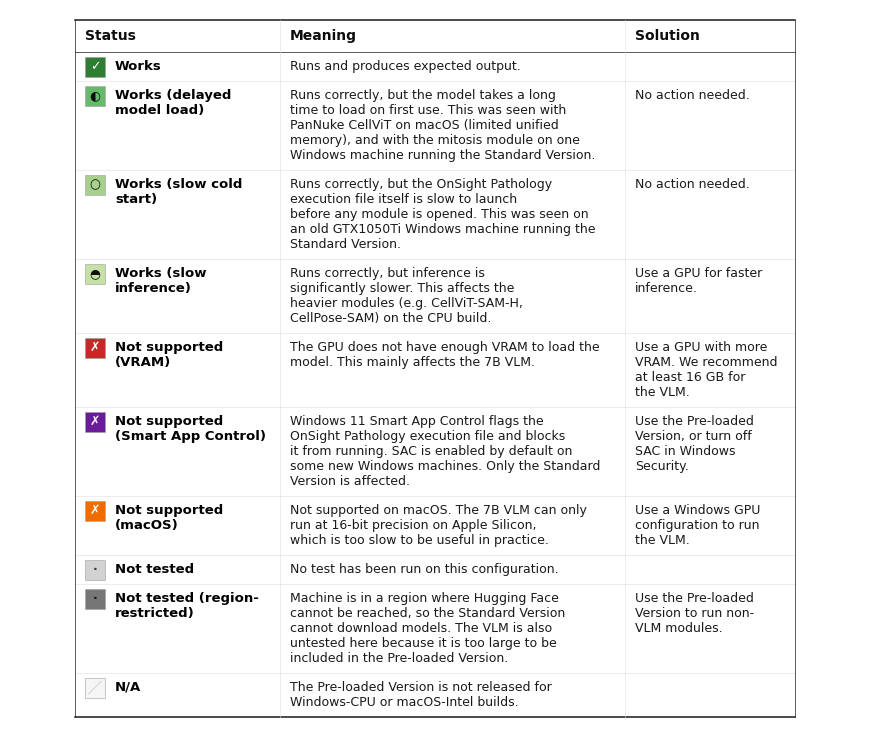

In [4]:
ENTRIES = [
    ("Works", "Works", "#2E7D32", "\u2713", "white", "Runs and produces expected output.", ""),
    ("Works_delay", "Works (delayed model load)", "#66BB6A", "\u25D0", "#0D0D0D",
     "Runs correctly, but the model takes a long time to load on first use. This was seen with PanNuke CellViT on macOS "
     "(limited unified memory), and with the mitosis module on one Windows machine running the Standard Version.", "No action needed."),
    ("Works_coldstart", "Works (slow cold start)", "#A8D08D", "\u25CB", "#0D0D0D",
     "Runs correctly, but the OnSight Pathology execution file itself is slow to launch before any module is opened. "
     "This was seen on an old GTX1050Ti Windows machine running the Standard Version.", "No action needed."),
    ("Works_slowinf", "Works (slow inference)", "#C5E1A5", "\u25D3", "#0D0D0D",
     "Runs correctly, but inference is significantly slower. This affects the heavier modules (e.g. CellViT-SAM-H, "
     "CellPose-SAM) on the CPU build.", "Use a GPU for faster inference."),
    ("NS_VRAM", "Not supported (VRAM)", "#C62828", "\u2717", "white",
     "The GPU does not have enough VRAM to load the model. This mainly affects the 7B VLM.",
     "Use a GPU with more VRAM. We recommend at least 16 GB for the VLM."),
    ("NS_SAC", "Not supported (Smart App Control)", "#6A1B9A", "\u2717", "white",
     "Windows 11 Smart App Control flags the OnSight Pathology execution file and blocks it from running. SAC is enabled "
     "by default on some new Windows machines. Only the Standard Version is affected.",
     "Use the Pre-loaded Version, or turn off SAC in Windows Security."),
    ("NS_macOS", "Not supported (macOS)", "#EF6C00", "\u2717", "white",
     "Not supported on macOS. The 7B VLM can only run at 16-bit precision on Apple Silicon, which is too slow to be useful in practice.",
     "Use a Windows GPU configuration to run the VLM."),
    ("NotTested", "Not tested", "#D2D2D2", "\u00B7", "#3A3A3A", "No test has been run on this configuration.", ""),
    ("NotTested_Region", "Not tested (region-restricted)", "#777676", "\u00B7", "#1A1A1A",
     "Machine is in a region where Hugging Face cannot be reached, so the Standard Version cannot download models. "
     "The VLM is also untested here because it is too large to be included in the Pre-loaded Version.",
     "Use the Pre-loaded Version to run non-VLM modules."),
    ("NA", "N/A", "#F5F5F5", "", "#9A9A9A", "The Pre-loaded Version is not released for Windows-CPU or macOS-Intel builds.", ""),
]
import textwrap
reset_style(**{"font.family": "DejaVu Sans", "axes.linewidth": 0.6})
PAGE_W, M_LEFT_T, M_TOP_T = 8.5, 0.65, 0.10
COL_W = (2.05, 3.45, 1.70); ROW_HEADER_H, ROW_PAD_V, ROW_PAD_H = 0.32, 0.07, 0.10
FS_HEADER, FS_STATUS, FS_BODY, CHAR_W_IN = 10.0, 9.5, 9.0, 0.072
LINE_H = FS_BODY * 1.20 / 72.0
def wrap(text, col_w):
    if not text: return [""]
    return textwrap.wrap(text, width=max(8, int((col_w - 2 * ROW_PAD_H) / CHAR_W_IN))) or [""]
rows = []
for key, label, color, sym, txt_col, meaning, solution in ENTRIES:
    sl, ml, so = wrap(label, COL_W[0] - 0.45), wrap(meaning, COL_W[1]), wrap(solution, COL_W[2])
    rows.append(dict(label=label, color=color, sym=sym, txt_col=txt_col, sl=sl, ml=ml, so=so,
                     h=max(len(sl), len(ml), len(so)) * LINE_H + 2 * ROW_PAD_V))
PAGE_H = M_TOP_T + ROW_HEADER_H + sum(r["h"] for r in rows) + 0.2
fig = plt.figure(figsize=(PAGE_W, PAGE_H))
ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, PAGE_W); ax.set_ylim(0, PAGE_H); ax.invert_yaxis(); ax.axis("off")
x0 = M_LEFT_T; x1 = x0 + COL_W[0]; x2 = x1 + COL_W[1]; x3 = x0 + sum(COL_W); hy = M_TOP_T
ax.plot([x0, x3], [hy, hy], color="#1A1A1A", lw=1.1)
for xx, t in [(x0, "Status"), (x1, "Meaning"), (x2, "Solution")]:
    ax.text(xx + ROW_PAD_H, hy + ROW_HEADER_H / 2, t, ha="left", va="center", fontsize=FS_HEADER, fontweight="bold", color="#0D0D0D")
cy = hy + ROW_HEADER_H; ax.plot([x0, x3], [cy, cy], color="#1A1A1A", lw=0.5)
SW = 0.20
for k, r in enumerate(rows):
    swx = x0 + ROW_PAD_H; swy = cy + ROW_PAD_V + 0.5 * LINE_H - SW / 2
    ax.add_patch(Rectangle((swx, swy), SW, SW, facecolor=r["color"], edgecolor="#9E9E9E", lw=0.4))
    if r["label"] == "N/A":
        ax.plot([swx + SW * 0.18, swx + SW * 0.82], [swy + SW * 0.82, swy + SW * 0.18], color="#D4D4D4", lw=0.7)
    if r["sym"]:
        ax.text(swx + SW / 2, swy + SW / 2, r["sym"], ha="center", va="center", fontsize=9, fontweight="bold", color=r["txt_col"])
    for li, line in enumerate(r["sl"]):
        ax.text(swx + SW + 0.10, cy + ROW_PAD_V + (li + 0.5) * LINE_H, line, ha="left", va="center", fontsize=FS_STATUS, fontweight="bold")
    for xx, lines in [(x1, r["ml"]), (x2, r["so"])]:
        for li, line in enumerate(lines):
            ax.text(xx + ROW_PAD_H, cy + ROW_PAD_V + (li + 0.5) * LINE_H, line, ha="left", va="center", fontsize=FS_BODY, color="#1A1A1A")
    cy += r["h"]
    if k < len(rows) - 1: ax.plot([x0, x3], [cy, cy], color="#DDDDDD", lw=0.4)
ax.plot([x0, x3], [cy, cy], color="#1A1A1A", lw=1.1)
for xx in (x1, x2): ax.plot([xx, xx], [hy, cy], color="#DDDDDD", lw=0.4)
for xx in (x0, x3): ax.plot([xx, xx], [hy, cy], color="#1A1A1A", lw=0.5)
save(fig, "Supp_Table1_status_legend", dpi=200)

## Supplementary Table 2

In [5]:
icpr = pd.read_csv(DATA / "Main_Figure" / "fig3" / "3c_ICPR_roc.csv")
icpr = icpr[icpr["Mitosis"].isin(["Yes", "No"])].copy()
icpr["score"] = pd.to_numeric(icpr["Confidence"], errors="coerce").fillna(0.0)
y = (icpr["Mitosis"] == "Yes").astype(int).to_numpy(); s = icpr["score"].to_numpy()
thr, *_ = youden(y, s)
pred = s >= thr
tp, fp, fn = int((pred & (y == 1)).sum()), int((pred & (y == 0)).sum()), int((~pred & (y == 1)).sum())
P, R = tp / (tp + fp), tp / (tp + fn); F = 2 * P * R / (P + R)
print(f"OnSight: n = {len(icpr)} detections ({y.sum()} mitoses); Youden threshold = {thr:.1f} (score >= threshold); "
      f"TP = {tp}, FP = {fp}, FN = {fn}")

st2 = pd.read_csv(DATA / "Supplementary_Table" / "Supp_Table_2_ICPR2012_leaderboard.csv")
table2 = pd.concat([pd.DataFrame({"Method": ["OnSight"], "Precision": [P], "Recall": [R], "F1": [F]}),
                    st2.loc[st2.Method != "OnSight", ["Method", "Precision", "Recall", "F1"]]], ignore_index=True)
table2.to_csv(OUT / "Supp_Table_2.csv", index=False, float_format="%.4f")
display(table2.style.format({"Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}"}).hide(axis="index"))

OnSight: n = 244 detections (97 mitoses); Youden threshold = 31.1 (score >= threshold); TP = 72, FP = 22, FN = 25


Method,Precision,Recall,F1
OnSight,0.7660,0.7423,0.7539
SUTECH,0.8243,0.6100,0.7011
IPAL,0.5591,0.7100,0.6256
NEC,0.7586,0.4400,0.5570
DEFINIENS,0.4615,0.3000,0.3636


## Supplementary Fig 7

n = 173 detections (48 Real, 125 Fake) from 15 images
AUC = 0.834
Youden threshold = 38.00 (0-100) = 0.38 (0-1); TPR = 0.750, FPR = 0.128
at threshold (score >= threshold): TP 36, FP 16, FN 12; precision = 0.69, recall = 0.75


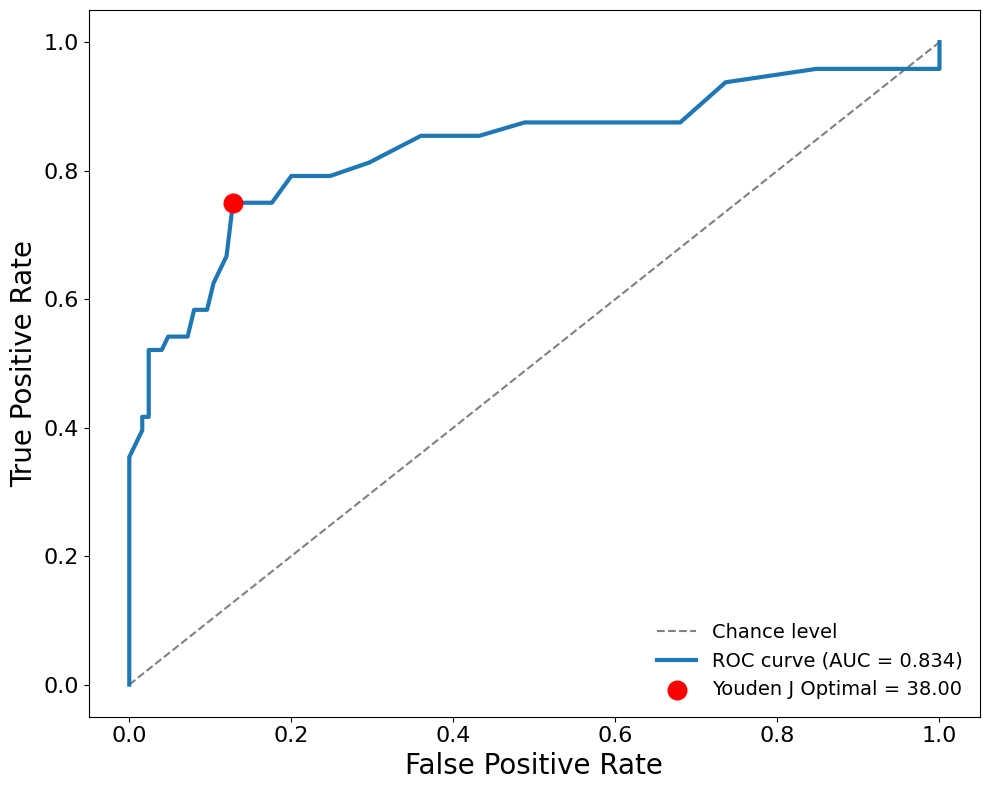

In [6]:
mid = pd.read_excel(SD / "fig7" / "MiDeSeC.xlsx")
y = (mid["Ground Truth"].str.strip() == "Real").astype(int).to_numpy()
s = mid["Confidence"].astype(float).to_numpy()
a = roc_auc_score(y, s)
thr, bf, bt, fpr, tpr, bi = youden(y, s)
pred = s >= thr
tp, fp, fn = int((pred & (y == 1)).sum()), int((pred & (y == 0)).sum()), int((~pred & (y == 1)).sum())
print(f"n = {len(y)} detections ({y.sum()} Real, {(y == 0).sum()} Fake) from {mid['Case ID'].nunique()} images")
print(f"AUC = {a:.3f}")
print(f"Youden threshold = {thr:.2f} (0-100) = {thr / 100:.2f} (0-1); TPR = {bt:.3f}, FPR = {bf:.3f}")
print(f"at threshold (score >= threshold): TP {tp}, FP {fp}, FN {fn}; precision = {tp / (tp + fp):.2f}, "
      f"recall = {tp / (tp + fn):.2f}")

reset_style()
fig = plt.figure(figsize=(10, 8))
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance level")
plt.plot(fpr, tpr, linewidth=3, label=f"ROC curve (AUC = {a:.3f})")
plt.scatter(bf, bt, color="red", s=180, label=f"Youden J Optimal = {thr:.2f}", zorder=5)
plt.xlabel("False Positive Rate", fontsize=20); plt.ylabel("True Positive Rate", fontsize=20)
plt.xticks(fontsize=16); plt.yticks(fontsize=16)
plt.legend(fontsize=14, loc="lower right", frameon=False)
plt.tight_layout()
save(fig, "SF7_MiDeSeC_ROC")

## Supplementary Figs 13, 14

In [7]:
for fig_no, fn in [("SF13", "fig13/Supp_Fig_13_ROI_detection_dice_scores.csv"), ("SF14", "fig14/Supp_Fig_14_ROI_detection_dice_scores.csv")]:
    t = pd.read_csv(SD / fn)
    print(f"{fig_no}: n = {len(t)} cases")
    display(t)
    num = t.select_dtypes("number")
    print("mean Dice:", num.mean().round(3).to_dict(), "\n")

SF13: n = 6 cases


,Case,Tumor_type,Cohort,Deconvolution_based_hotspot_detection_Dice,Image_feature_based_patch_clustering_Dice
0,Case_1,Brain metastasis,Local UHN,0.860,0.754
1,Case_2,Brain metastasis,Local UHN,0.847,0.711
2,Case_3,Brain metastasis,Local UHN,0.959,0.930
3,Case_4,Glioma,Local UHN,0.802,0.712
4,Case_5,Oligodendroglioma,TCGA-LGG,0.805,0.878
5,Case_6,Meningioma,Local UHN,0.863,0.806


mean Dice: {'Deconvolution_based_hotspot_detection_Dice': 0.856, 'Image_feature_based_patch_clustering_Dice': 0.799} 

SF14: n = 4 cases


,Case,Tumor_type,Deconvolution_based_hotspot_detection_Dice,Image_feature_based_patch_clustering_Dice
0,Case_1,Clear cell renal cell carcinoma,0.431,0.913
1,Case_2,Clear cell renal cell carcinoma,0.583,0.942
2,Case_3,Skin melanoma,0.420,0.966
3,Case_4,Glioma,0.541,0.922


mean Dice: {'Deconvolution_based_hotspot_detection_Dice': 0.494, 'Image_feature_based_patch_clustering_Dice': 0.936} 



## Supplementary Fig 15

In [8]:
FOLDER_MAP = {"Astros_G2": "Astro_G2", "Astros_G3": "Astro_G3", "Astros_G4": "Astro_G4", "Gbm": "GBM",
              "Oligos_G2": "Oligos_G2", "Oligos_G3": "Oligos_G3"}
SIZE_SHAPE = ["Size.Area_mean", "Size.Perimeter_mean", "Size.MajorAxisLength_mean", "Size.MinorAxisLength_mean",
              "Shape.EquivalentDiameter_mean", "Shape.Circularity_mean", "Shape.Eccentricity_mean",
              "Shape.Solidity_mean", "Shape.Extent_mean"]
INTENSITY = ["Nucleus.Intensity.Mean_mean", "Nucleus.Intensity.Std_mean", "Nucleus.Intensity.IQR_mean"]
NICE = {"Size.Area_mean": "Area", "Size.Perimeter_mean": "Perimeter", "Size.MajorAxisLength_mean": "Major axis length",
        "Size.MinorAxisLength_mean": "Minor axis length", "Shape.EquivalentDiameter_mean": "Equivalent diameter",
        "Shape.Circularity_mean": "Circularity", "Shape.Eccentricity_mean": "Eccentricity", "Shape.Solidity_mean": "Solidity",
        "Shape.Extent_mean": "Extent", "Nucleus.Intensity.Mean_mean": "Intensity mean",
        "Nucleus.Intensity.Std_mean": "Intensity SD", "Nucleus.Intensity.IQR_mean": "Intensity IQR"}
PANELS = {"A": ("A_uncalibrated_size_shape", SIZE_SHAPE), "B": ("B_uncalibrated_intensity", INTENSITY),
          "C": ("C_calibrated_size_shape", SIZE_SHAPE), "D": ("D_calibrated_intensity", INTENSITY)}
sf15 = {p: pd.read_csv(SD / "fig15" / f"{f}.csv") for p, (f, _) in PANELS.items()}
for p, d in sf15.items():
    d["Group"] = d["folder"].map(FOLDER_MAP)
    print(f"{p}: {len(d)} patches, {d.groupby(['folder', 'subfolder']).ngroups} subjects, "
          f"patches/subject = {sorted(d.groupby(['folder', 'subfolder']).size().unique())}, per group = {d.Group.value_counts().sort_index().to_dict()}")

rows = []
for p, (f, feats) in PANELS.items():
    d = sf15[p]
    for ft in feats:
        x, yv = d["CellProfiler_" + ft].to_numpy(float), d["OnSight_" + ft].to_numpy(float)
        lr = stats.linregress(x, yv); pf = pearson_fisher(x, yv)
        rows.append(dict(panel=p, source_file=f + ".csv", feature=ft, n=pf["n"], df=pf["df"], r=pf["r"],
                         ci_low=pf["ci_low"], ci_high=pf["ci_high"], p=lr.pvalue, slope=lr.slope, intercept=lr.intercept))
corr15 = pd.DataFrame(rows)
corr15.to_csv(OUT / "SF15_correlations.csv", index=False)
display(corr15.style.format({"r": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}", "p": "{:.2e}",
                             "slope": "{:.3f}", "intercept": "{:.3f}"}))
ss = corr15[corr15.panel.isin(["A", "C"])]; it = corr15[corr15.panel.isin(["B", "D"])]
print(f"size/shape r(238) range {ss.r.min():.3f}-{ss.r.max():.3f}; intensity r(238) range {it.r.min():.3f}-{it.r.max():.3f}")

def bias(d, ft):
    cp, os_ = d["CellProfiler_" + ft], d["OnSight_" + ft]
    return 100 * (os_.mean() - cp.mean()) / cp.mean()
b_unc, b_cal = bias(sf15["A"], "Size.Area_mean"), bias(sf15["C"], "Size.Area_mean")
b_sd, b_iqr = bias(sf15["B"], "Nucleus.Intensity.Std_mean"), bias(sf15["B"], "Nucleus.Intensity.IQR_mean")
print(f"mean nuclear area, OnSight vs CellProfiler: uncalibrated {b_unc:+.1f}%, calibrated {b_cal:+.1f}%")
print("all size features (uncalibrated -> calibrated):",
      {NICE[f]: f"{bias(sf15['A'], f):+.1f}% -> {bias(sf15['C'], f):+.1f}%" for f in SIZE_SHAPE[:5]})
print(f"intensity SD {b_sd:+.1f}%, intensity IQR {b_iqr:+.1f}%, intensity mean {bias(sf15['B'], 'Nucleus.Intensity.Mean_mean'):+.1f}%")

AGGR = ["GBM", "Astro_G4", "Astro_G3", "Oligos_G3", "Astro_G2", "Oligos_G2"]
for name, feat in [("eccentricity", "Shape.Eccentricity_mean"), ("circularity", "Shape.Circularity_mean")]:
    e = pd.read_csv(SD / "fig15" / f"E_{name}.csv"); e["Group"] = e.folder.map(FOLDER_MAP)
    subj = e.groupby(["Group", "subfolder"], as_index=False)[feat].mean()
    groups = [subj.loc[subj.Group == g, feat] for g in AGGR]
    res = stats.f_oneway(*groups)
    k, N = len(groups), sum(len(g) for g in groups)
    print(f"E {name}: n = {N} subjects ({', '.join(f'{g} {len(x)}' for g, x in zip(AGGR, groups))}); "
          f"F({k - 1}, {N - k}) = {res.statistic:.2f}, p = {res.pvalue:.2e}; "
          f"eta^2 = {res.statistic * (k - 1) / (res.statistic * (k - 1) + N - k):.3f}")

A: 240 patches, 48 subjects, patches/subject = [5], per group = {'Astro_G2': 40, 'Astro_G3': 40, 'Astro_G4': 40, 'GBM': 40, 'Oligos_G2': 40, 'Oligos_G3': 40}
B: 240 patches, 48 subjects, patches/subject = [5], per group = {'Astro_G2': 40, 'Astro_G3': 40, 'Astro_G4': 40, 'GBM': 40, 'Oligos_G2': 40, 'Oligos_G3': 40}
C: 240 patches, 48 subjects, patches/subject = [5], per group = {'Astro_G2': 40, 'Astro_G3': 40, 'Astro_G4': 40, 'GBM': 40, 'Oligos_G2': 40, 'Oligos_G3': 40}
D: 240 patches, 48 subjects, patches/subject = [5], per group = {'Astro_G2': 40, 'Astro_G3': 40, 'Astro_G4': 40, 'GBM': 40, 'Oligos_G2': 40, 'Oligos_G3': 40}


,panel,source_file,feature,n,df,r,ci_low,ci_high,p,slope,intercept
0,A,A_uncalibrated_size_shape.csv,Size.Area_mean,240,238,0.998,0.998,0.999,2.37e-296,1.210,0.029
1,A,A_uncalibrated_size_shape.csv,Size.Perimeter_mean,240,238,0.998,0.997,0.998,2.86e-280,1.103,-0.036
2,A,A_uncalibrated_size_shape.csv,Size.MajorAxisLength_mean,240,238,0.997,0.996,0.997,6.73e-260,1.103,-0.011
3,A,A_uncalibrated_size_shape.csv,Size.MinorAxisLength_mean,240,238,0.998,0.997,0.998,1.42e-277,1.102,-0.009
4,A,A_uncalibrated_size_shape.csv,Shape.EquivalentDiameter_mean,240,238,0.998,0.997,0.998,2.95e-284,1.102,-0.009
5,A,A_uncalibrated_size_shape.csv,Shape.Circularity_mean,240,238,0.966,0.957,0.974,4.21e-142,0.959,0.035
6,A,A_uncalibrated_size_shape.csv,Shape.Eccentricity_mean,240,238,0.992,0.989,0.994,8.13e-215,1.001,-0.000
7,A,A_uncalibrated_size_shape.csv,Shape.Solidity_mean,240,238,0.985,0.981,0.988,1.57e-183,0.987,0.013
8,A,A_uncalibrated_size_shape.csv,Shape.Extent_mean,240,238,0.984,0.979,0.987,5.31e-179,0.991,0.006
9,B,B_uncalibrated_intensity.csv,Nucleus.Intensity.Mean_mean,240,238,0.939,0.922,0.953,1.51e-112,1.002,-0.013


size/shape r(238) range 0.966-0.998; intensity r(238) range 0.822-0.939
mean nuclear area, OnSight vs CellProfiler: uncalibrated +21.1%, calibrated +0.8%
all size features (uncalibrated -> calibrated): {'Area': '+21.1% -> +0.8%', 'Perimeter': '+10.1% -> +0.4%', 'Major axis length': '+10.1% -> +0.5%', 'Minor axis length': '+10.0% -> +0.3%', 'Equivalent diameter': '+10.1% -> +0.4%'}
intensity SD +36.8%, intensity IQR +35.2%, intensity mean -4.2%
E eccentricity: n = 48 subjects (GBM 8, Astro_G4 8, Astro_G3 8, Oligos_G3 8, Astro_G2 8, Oligos_G2 8); F(5, 42) = 10.11, p = 2.10e-06; eta^2 = 0.546
E circularity: n = 48 subjects (GBM 8, Astro_G4 8, Astro_G3 8, Oligos_G3 8, Astro_G2 8, Oligos_G2 8); F(5, 42) = 7.69, p = 3.32e-05; eta^2 = 0.478


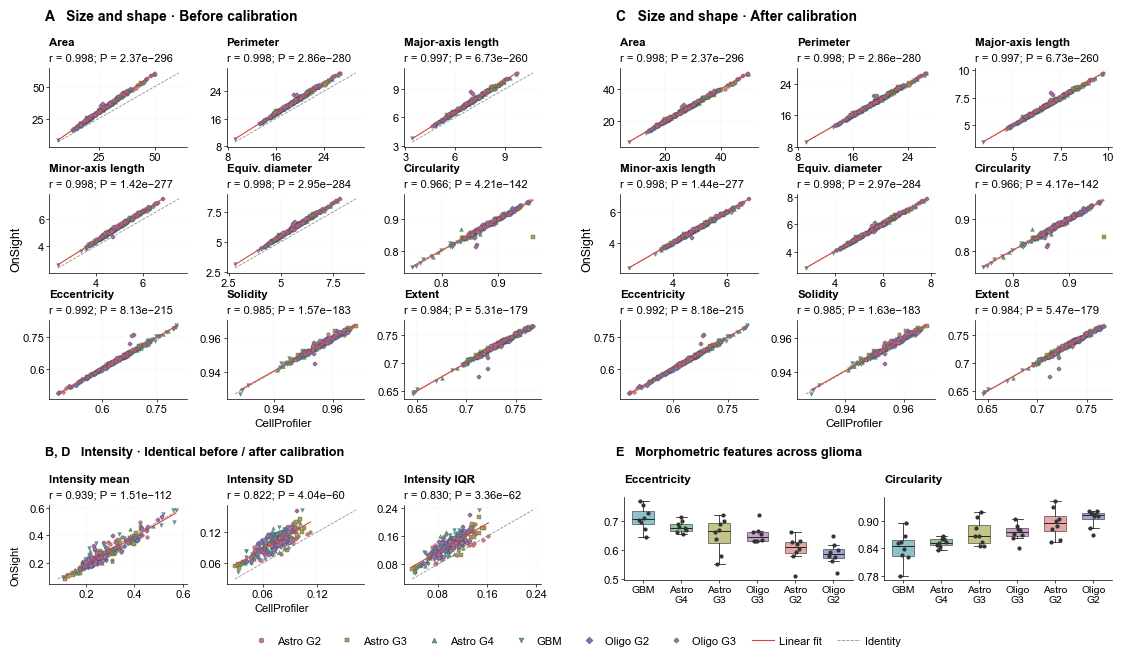

In [9]:
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
from PIL import Image

A4_RC = {"font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"],
         "font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8, "xtick.labelsize": 8,
         "ytick.labelsize": 8, "axes.linewidth": .5, "axes.spines.right": False,
         "axes.spines.top": False, "pdf.fonttype": 42, "svg.fonttype": "none",
         "legend.frameon": False, "savefig.facecolor": "white"}
A4_GROUPS = ["Astros_G2", "Astros_G3", "Astros_G4", "Gbm", "Oligos_G2", "Oligos_G3"]
A4_DISPLAY = ["Astro G2", "Astro G3", "Astro G4", "GBM", "Oligo G2", "Oligo G3"]
A4_COLORS = ["#d87878", "#a5a349", "#5aa869", "#51a2af", "#6b79b7", "#ab70ac"]
A4_MARKERS = ["o", "s", "^", "v", "D", "P"]
A4_FEATURES = ["Size.Area", "Size.Perimeter", "Size.MajorAxisLength", "Size.MinorAxisLength",
               "Shape.EquivalentDiameter", "Shape.Circularity", "Shape.Eccentricity", "Shape.Solidity", "Shape.Extent"]
A4_NAMES = ["Area", "Perimeter", "Major-axis length", "Minor-axis length", "Equiv. diameter",
            "Circularity", "Eccentricity", "Solidity", "Extent"]

def mm_text(fig, x, y, s, **kw):
    w, h = np.asarray(fig.get_size_inches()) * 25.4
    return fig.text(x / w, 1 - y / h, s, va="top", **kw)

def mm_axes(fig, x, y, w, h, label):
    fw, fh = np.asarray(fig.get_size_inches()) * 25.4
    return fig.add_axes([x / fw, 1 - (y + h) / fh, w / fw, h / fh], label=label)

def stat_label(r, p):
    return f"r = {r:.3f}; P = {p:.2e}".replace("e-", "e−")

def a4_scatter(fig, x, y, w, h, df, feature, title, label_text, ref="CellProfiler", groups=True, label=""):
    ax = mm_axes(fig, x, y, w, h, label)
    xv = df[ref + "_" + feature].to_numpy(); yv = df["OnSight_" + feature].to_numpy()
    if groups:
        for group, color, marker in zip(A4_GROUPS, A4_COLORS, A4_MARKERS):
            sel = df.folder.eq(group).to_numpy()
            ax.scatter(xv[sel], yv[sel], s=7, c=color, marker=marker, edgecolors="#404040", linewidths=.2, zorder=3)
    else:
        ax.scatter(xv, yv, s=11, c="#3e55cd", edgecolors="none", zorder=3)
    slope, intercept = np.polyfit(xv, yv, 1)
    xx = np.array([xv.min(), xv.max()])
    ax.plot(xx, slope * xx + intercept, color="#d3483d", lw=.8, zorder=4)
    lo = min(xv.min(), yv.min()); hi = max(xv.max(), yv.max()); pad = (hi - lo) * .07
    ax.set_xlim(lo - pad, hi + pad); ax.set_ylim(lo - pad, hi + pad)
    ax.plot([lo, hi], [lo, hi], color="#919191", ls="--", lw=.6, zorder=1)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=3, min_n_ticks=2))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=3, min_n_ticks=2))
    fmt = FuncFormatter(lambda v, p: f"{v:.3g}")
    ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
    ax.tick_params(length=2, pad=1.5, width=.5)
    ax.grid(alpha=.14, lw=.35)
    mm_text(fig, x, y - 8, title, fontsize=8.3, weight="bold")
    mm_text(fig, x, y - 3.9, label_text, fontsize=8)
    return ax

def save_a4(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=300, bbox_inches="tight", pad_inches=0.05)
    fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight", pad_inches=0.05)
    plt.show()

def sf15_label(panel, feature):
    row = corr15[(corr15.panel == panel) & (corr15.feature == feature)].iloc[0]
    return stat_label(row.r, row.p)

reset_style(**A4_RC)
fig = plt.figure(figsize=(297 / 25.4, 210 / 25.4))
mm_text(fig, 14, 12, "A   Size and shape · Before calibration", fontsize=10, weight="bold")
mm_text(fig, 159, 12, "C   Size and shape · After calibration", fontsize=10, weight="bold")
for b, panel in enumerate(["A", "C"]):
    df = sf15[panel]
    for k, (feature, title) in enumerate(zip(A4_FEATURES, A4_NAMES)):
        r, c = divmod(k, 3)
        a4_scatter(fig, 15 + b * 145 + c * 45, 27 + r * 32, 35, 20, df, feature + "_mean", title,
                   sf15_label(panel, feature + "_mean"), label=f"{b}_{r}_{c}")
mm_text(fig, 5, 67, "OnSight", rotation=90, fontsize=9)
mm_text(fig, 150, 67, "OnSight", rotation=90, fontsize=9)
mm_text(fig, 67, 116, "CellProfiler", fontsize=8.5)
mm_text(fig, 212, 116, "CellProfiler", fontsize=8.5)
mm_text(fig, 14, 123, "B, D   Intensity · Identical before / after calibration", fontsize=9.2, weight="bold")
for k, (f, n) in enumerate(zip(["Mean", "Std", "IQR"], ["Intensity mean", "Intensity SD", "Intensity IQR"])):
    feat = "Nucleus.Intensity." + f + "_mean"
    a4_scatter(fig, 15 + k * 45, 138, 35, 20, sf15["B"], feat, n, sf15_label("B", feat), label=f"I{k}")
mm_text(fig, 5, 148, "OnSight", rotation=90, fontsize=8)
mm_text(fig, 67, 163, "CellProfiler", fontsize=8)
mm_text(fig, 159, 123, "E   Morphometric features across glioma", fontsize=9.2, weight="bold")
order = ["Gbm", "Astros_G4", "Astros_G3", "Oligos_G3", "Astros_G2", "Oligos_G2"]
names = ["GBM", "Astro\nG4", "Astro\nG3", "Oligo\nG3", "Astro\nG2", "Oligo\nG2"]
for k, (f, n) in enumerate([("E_eccentricity.csv", "Eccentricity"), ("E_circularity.csv", "Circularity")]):
    df = pd.read_csv(SD / "fig15" / f); value = df.columns[0]
    agg = df.groupby(["folder", "subfolder"])[value].mean()
    arr = [agg.loc[g].to_numpy() for g in order]
    ax = mm_axes(fig, 161 + k * 66, 136, 58, 21, "E" + str(k))
    bp = ax.boxplot(arr, patch_artist=True, widths=.57, showfliers=False,
                    medianprops={"color": "#222", "linewidth": .7}, boxprops={"linewidth": .5},
                    whiskerprops={"linewidth": .5}, capprops={"linewidth": .5})
    for j, (a, g, patch) in enumerate(zip(arr, order, bp["boxes"])):
        patch.set_facecolor(A4_COLORS[A4_GROUPS.index(g)]); patch.set_alpha(.65)
        ax.scatter(j + 1 + np.linspace(-.12, .12, len(a)), a, s=4, c="#333", zorder=3)
    ax.set_xticks(range(1, 7), names, fontsize=7.5)
    ax.tick_params(length=2, pad=1.5, width=.5)
    ax.yaxis.set_major_locator(MaxNLocator(3))
    mm_text(fig, 161 + k * 66, 130, n, fontsize=8.5, weight="bold")
handles = [Line2D([], [], marker=m, color="none", markerfacecolor=c, markeredgecolor="#444", markeredgewidth=.3,
                  markersize=3.5, label=n) for m, c, n in zip(A4_MARKERS, A4_COLORS, A4_DISPLAY)]
handles += [Line2D([], [], color="#d3483d", lw=.8, label="Linear fit"),
            Line2D([], [], color="#919191", ls="--", lw=.6, label="Identity")]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(.5, 1 - 170 / 210), ncol=8, fontsize=8,
           handletextpad=.45, columnspacing=1.4, borderaxespad=0)
save_a4(fig, "SF15_CellProfiler_comparison")

## Supplementary Fig 16

In [10]:
seg = pd.read_csv(SD / "fig16" / "B_segmentation_metrics.csv", encoding="utf-8-sig")
METRICS = ["Dice Score", "F1-Score", "Precision", "Recall"]
print(f"B: n = {len(seg)} patches, manual nuclei = {seg.cells.sum():,} (range {seg.cells.min()}-{seg.cells.max()} per patch)")
display(seg[METRICS].describe().loc[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].round(4))

mc = pd.read_csv(SD / "fig16" / "C_manual_correlation.csv")
feats16 = [c[len("Manual_"):] for c in mc.columns if c.startswith("Manual_") and c not in ("Manual_Patch_ID", "Manual_Nuclei_Count")]
print(f"C: n = {len(mc)} patches, {len(feats16)} features")
rows = []
for ft in feats16:
    x, yv = mc["Manual_" + ft].to_numpy(float), mc["OnSight_" + ft].to_numpy(float)
    pf = pearson_fisher(x, yv)
    rows.append(dict(feature=ft, n=pf["n"], df=pf["df"], r=pf["r"], ci_low=pf["ci_low"], ci_high=pf["ci_high"], p=pf["p"]))
corr16 = pd.DataFrame(rows)
corr16.to_csv(OUT / "SF16C_correlations.csv", index=False)
display(corr16.style.format({"r": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}", "p": "{:.2e}"}))
print(f"r(8) {corr16.r.min():.3f}-{corr16.r.max():.3f}; lower 95% CI bounds {corr16.ci_low.min():.3f}-{corr16.ci_low.max():.3f}; max p {corr16.p.max():.1e}")

B: n = 10 patches, manual nuclei = 1,555 (range 91-242 per patch)


,Dice Score,F1-Score,Precision,Recall
count,10.0000,10.0000,10.0000,10.0000
mean,0.8704,0.9348,0.9666,0.9056
std,0.0253,0.0229,0.0193,0.0350
min,0.8229,0.8997,0.9346,0.8553
25%,0.8567,0.9164,0.9545,0.8828
50%,0.8684,0.9312,0.9664,0.9030
75%,0.8907,0.9554,0.9768,0.9364
max,0.9076,0.9645,1.0000,0.9518


C: n = 10 patches, 24 features


,feature,n,df,r,ci_low,ci_high,p
0,Size.Area_mean,10,8,0.973,0.885,0.994,2.37e-06
1,Size.Perimeter_mean,10,8,0.967,0.864,0.992,4.81e-06
2,Size.MajorAxisLength_mean,10,8,0.972,0.884,0.994,2.49e-06
3,Size.MinorAxisLength_mean,10,8,0.973,0.888,0.994,2.12e-06
4,Shape.EquivalentDiameter_mean,10,8,0.972,0.882,0.994,2.62e-06
5,Shape.Eccentricity_mean,10,8,0.996,0.981,0.999,1.66e-09
6,Shape.Extent_mean,10,8,0.908,0.650,0.978,2.80e-04
7,Nucleus.Intensity.Mean_mean,10,8,0.983,0.928,0.996,3.39e-07
8,Size.Area_median,10,8,0.975,0.896,0.994,1.57e-06
9,Size.Perimeter_median,10,8,0.977,0.903,0.995,1.16e-06


r(8) 0.895-0.996; lower 95% CI bounds 0.607-0.981; max p 4.7e-04


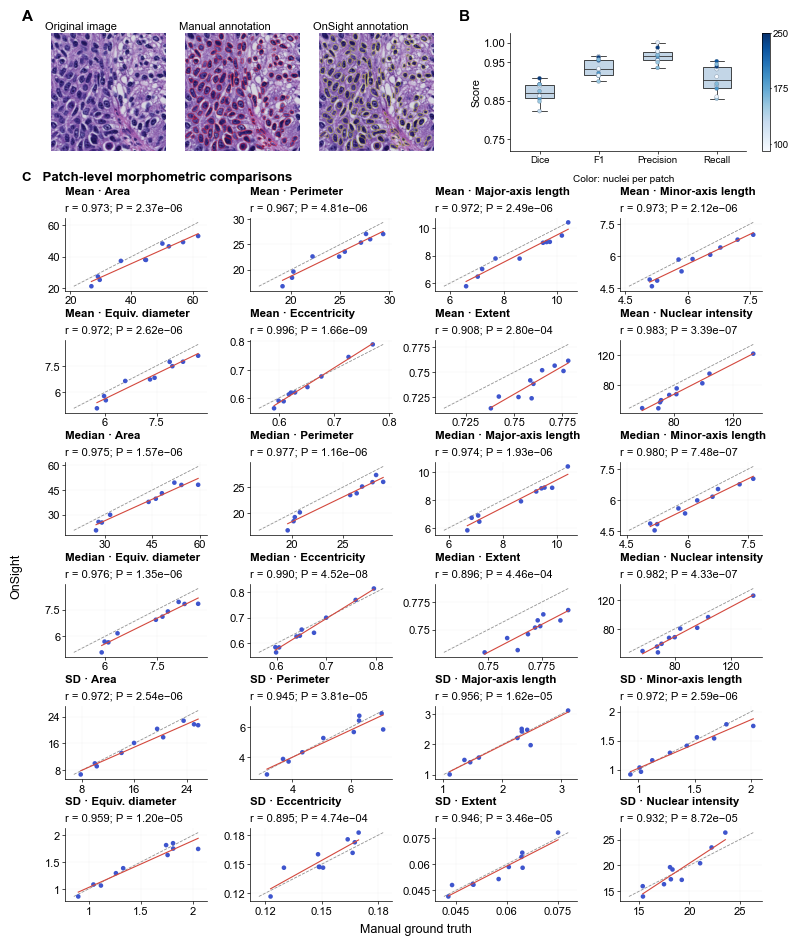

In [11]:
ASSETS = Path("figure_assets")
reset_style(**A4_RC)
fig = plt.figure(figsize=(210 / 25.4, 297 / 25.4))
mm_text(fig, 8, 12, "A", fontsize=11, weight="bold")
for k, (file, title) in enumerate([("SF16A_original_image.png", "Original image"),
                                   ("SF16A_manual_annotation.png", "Manual annotation"),
                                   ("SF16A_onsight_annotation.png", "OnSight annotation")]):
    ax = mm_axes(fig, 14 + k * 34, 18, 32, 30, "image" + str(k))
    im = Image.open(ASSETS / file)
    if k == 2:
        im = im.crop((7, 23, 567, 601))
    ax.imshow(im); ax.set_axis_off()
    mm_text(fig, 14 + k * 34, 15, title, fontsize=8)
mm_text(fig, 119, 12, "B", fontsize=11, weight="bold")
ax = mm_axes(fig, 132, 18, 60, 30, "segmentation")
arr = [seg[c] for c in ["Dice Score", "F1-Score", "Precision", "Recall"]]
bp = ax.boxplot(arr, patch_artist=True, widths=.48, showfliers=False,
                medianprops={"color": "#333", "linewidth": .6}, boxprops={"linewidth": .5},
                whiskerprops={"linewidth": .5}, capprops={"linewidth": .5})
for patch in bp["boxes"]:
    patch.set_facecolor("#c3d6e7")
for j, a in enumerate(arr):
    pts = ax.scatter(np.full(len(a), j + 1), a, c=seg.cells, cmap="Blues", vmin=90, vmax=250, s=8, linewidths=.2,
                     edgecolors="#586c83", zorder=3)
ax.set_xticks([1, 2, 3, 4], ["Dice", "F1", "Precision", "Recall"], fontsize=7)
ax.set_ylim(.72, 1.025); ax.set_yticks([.75, .85, .95, 1.0]); ax.tick_params(length=2, pad=1, width=.5)
ax.set_ylabel("Score", labelpad=2)
cax = mm_axes(fig, 196, 18, 2, 30, "colorbar"); fig.colorbar(pts, cax=cax, ticks=[100, 175, 250])
cax.tick_params(labelsize=7, length=1, pad=1)
mm_text(fig, 161, 54, "Color: nuclei per patch", fontsize=7.3, ha="center")
mm_text(fig, 8, 53, "C   Patch-level morphometric comparisons", fontsize=9.5, weight="bold")
feats = ["Size.Area", "Size.Perimeter", "Size.MajorAxisLength", "Size.MinorAxisLength",
         "Shape.EquivalentDiameter", "Shape.Eccentricity", "Shape.Extent", "Nucleus.Intensity.Mean"]
names = ["Area", "Perimeter", "Major-axis length", "Minor-axis length", "Equiv. diameter", "Eccentricity", "Extent",
         "Nuclear intensity"]
stat16 = corr16.set_index("feature")
for j, (summary, lab) in enumerate([("mean", "Mean"), ("median", "Median"), ("std", "SD")]):
    for k, (f, n) in enumerate(zip(feats, names)):
        r, c = divmod(k, 4); row = j * 2 + r
        ft = f + "_" + summary
        a4_scatter(fig, 19 + c * 47, 65 + row * 31, 36, 18.5, mc, ft, lab + " · " + n,
                   stat_label(stat16.loc[ft, "r"], stat16.loc[ft, "p"]), ref="Manual", groups=False, label=f"c{row}{c}")
mm_text(fig, 5, 150, "OnSight", rotation=90, fontsize=9)
mm_text(fig, 108, 244, "Manual ground truth", ha="center", fontsize=9)
save_a4(fig, "SF16_manual_vs_OnSight")

## Supplementary Fig 17

n = 64; median cutoff = 58.915; univariate Cox coefficient = -0.0798; high risk = feature < cutoff
high 32 (9 deaths), low 32 (1 deaths)
two-sided log-rank chi2(1) = 13.04, p = 3.050e-04
median OS, high-risk group: 46.0 months


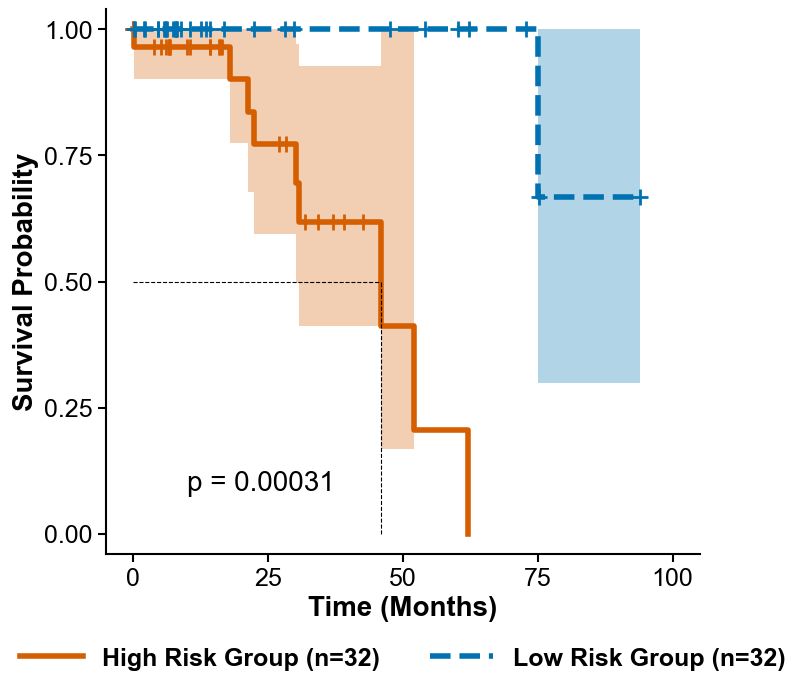

In [12]:
km = pd.read_csv(SD / "fig17" / "Oligos_G3_top_feature_survival_data.csv")
FEAT = "Nucleus.Intensity.Mean_median"
cut = km[FEAT].median()
cph = CoxPHFitter().fit(km[["os_months", "os_event", FEAT]], "os_months", "os_event")
coef = cph.params_[FEAT]
km["risk_group"] = np.where(km[FEAT] >= cut, "high", "low") if coef > 0 else np.where(km[FEAT] < cut, "high", "low")
print(f"n = {len(km)}; median cutoff = {cut:.3f}; univariate Cox coefficient = {coef:.4f}; high risk = feature "
      f"{'>=' if coef > 0 else '<'} cutoff")
hi, lo_ = km[km.risk_group == "high"], km[km.risk_group == "low"]
lr = logrank_test(hi.os_months, lo_.os_months, hi.os_event, lo_.os_event)
print(f"high {len(hi)} ({int(hi.os_event.sum())} deaths), low {len(lo_)} ({int(lo_.os_event.sum())} deaths)")
print(f"two-sided log-rank chi2(1) = {lr.test_statistic:.2f}, p = {lr.p_value:.3e}")

def r_log_ci(kmf, z=1.959964):
    et = kmf.event_table
    n, d = et["at_risk"].to_numpy(float), et["observed"].to_numpy(float)
    with np.errstate(divide="ignore", invalid="ignore"):
        inc = np.where(d > 0, d / (n * (n - d)), 0.0)
    se = np.sqrt(np.cumsum(inc))
    S = kmf.survival_function_.iloc[:, 0].to_numpy()
    lo = np.where(S > 0, S * np.exp(-z * se), np.nan); up = np.where(S > 0, np.minimum(1, S * np.exp(z * se)), np.nan)
    lo[~np.isfinite(se)] = np.nan; up[~np.isfinite(se)] = np.nan
    return et.index.to_numpy(), S, lo, up

reset_style(**{"font.family": "sans-serif", "font.sans-serif": SANS})
fig, ax = plt.subplots(figsize=(8, 7))
for g, col, ls in [("high", "#D55E00", "-"), ("low", "#0072B2", "--")]:
    sub = km[km.risk_group == g]
    kmf = KaplanMeierFitter().fit(sub.os_months, sub.os_event, label=g)
    t, S, lo, up = r_log_ci(kmf)
    ax.fill_between(t, lo, up, step="post", color=col, alpha=0.3, linewidth=0)
    ax.step(t, S, where="post", color=col, linestyle=ls, linewidth=4,
            label=f"{'High' if g == 'high' else 'Low'} Risk Group (n={len(sub)})")
    cens = sub.loc[sub.os_event == 0, "os_months"].to_numpy()
    ax.plot(cens, kmf.survival_function_at_times(cens).to_numpy(), "+", color=col, markersize=11, markeredgewidth=2)
    med = kmf.median_survival_time_
    if np.isfinite(med):
        ax.plot([0, med], [0.5, 0.5], "k--", lw=0.8); ax.plot([med, med], [0, 0.5], "k--", lw=0.8)
        print(f"median OS, {g}-risk group: {med:.1f} months")
ax.text(10, 0.10, f"p = {lr.p_value:.2g}", fontsize=20, ha="left", va="center")
ax.set_xlabel("Time (Months)", fontsize=20, fontweight="bold"); ax.set_ylabel("Survival Probability", fontsize=20, fontweight="bold")
ax.set_xticks([0, 25, 50, 75, 100]); ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(["0.00", "0.25", "0.50", "0.75", "1.00"])
ax.tick_params(labelsize=18, width=1.5, length=6)
ax.set_xlim(-5, 105); ax.set_ylim(-0.04, 1.04)
for sname in ("top", "right"): ax.spines[sname].set_visible(False)
for sname in ("left", "bottom"): ax.spines[sname].set_linewidth(1.5)
leg = ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False, fontsize=18, handlelength=2.5,
                prop={"weight": "bold", "size": 18})
fig.tight_layout()
save(fig, "SF17_KM_top_feature")

## Supplementary Fig 18

in-distribution WSIs = 1409
per class: {'Epithelial pattern': 47, 'Glial histology': 943, 'Meningothelial Histology': 344, 'Schwannian histology': 75}


Pred_argmax,Epithelial pattern,Glial histology,Meningothelial Histology,Schwannian histology,total
Subclass,,,,,
Metastatic,40,6,0,1,47
Anaplastic Astro IDH Mutant,0,47,0,0,47
Anaplastic Ependymoma,0,50,0,0,50
Anaplastic Oligo 1p-19q Codel,0,91,0,0,91
Astrocytoma Pleomorphic,0,1,0,0,1
Diffuse Astrocytoma IDH Mutant,0,50,0,0,50
Ependymoma,0,44,2,0,46
GBM IDH Mutant,0,34,0,0,34
GBM IDH Wildtype,0,469,0,0,469


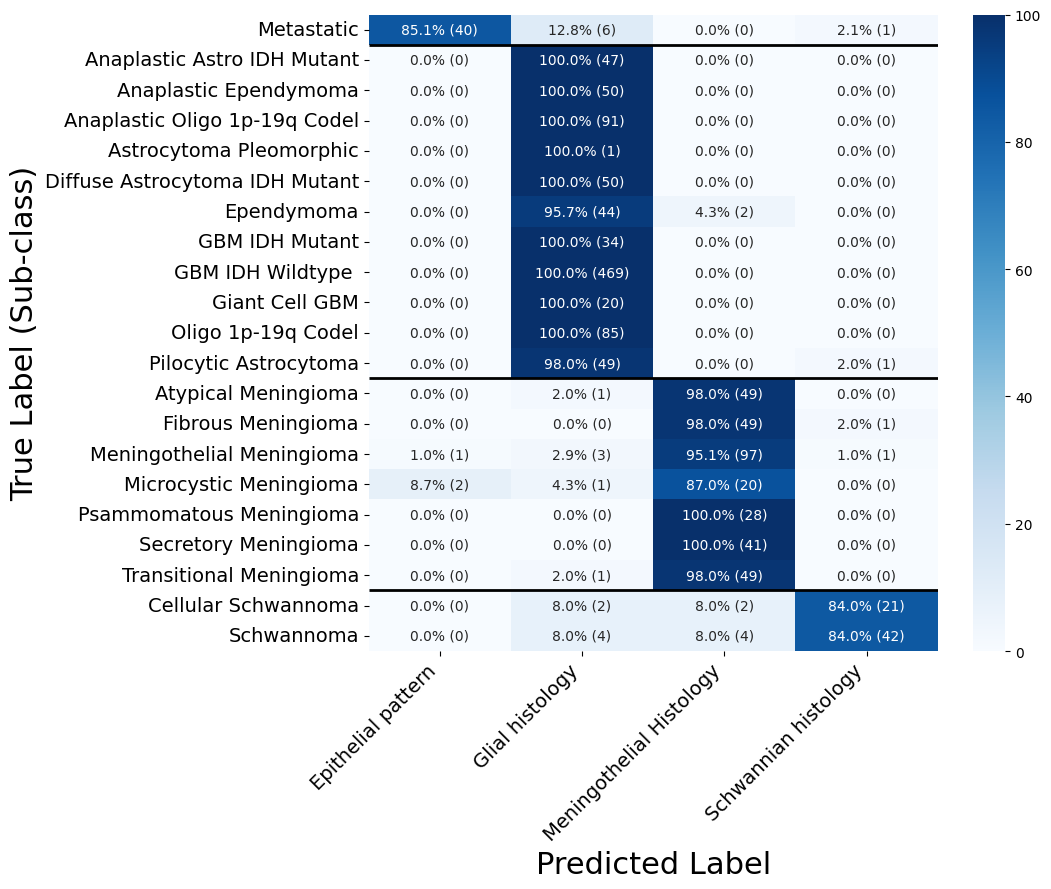

In [13]:
UMB = ["Epithelial pattern", "Glial histology", "Meningothelial Histology", "Schwannian histology"]
eb = pd.read_csv(SD / "fig18" / "4_class_tumor_ViT_ebrains.csv")
df18 = eb[eb.InDist == 1].copy()
df18["Pred_argmax"] = df18[UMB].idxmax(axis=1)
print(f"in-distribution WSIs = {len(df18)}")
print("per class:", df18.Class.value_counts().reindex(UMB).to_dict())
cm = pd.crosstab(df18["Subclass"], df18["Pred_argmax"], dropna=False).reindex(columns=UMB, fill_value=0)
row_order, bounds, start = [], [], 0
for u in UMB:
    subs = sorted(df18.loc[df18["Class"] == u, "Subclass"].unique())
    row_order.extend(subs); start += len(subs); bounds.append(start)
cm = cm.reindex(row_order)
cm_perc = cm.div(cm.sum(axis=1), axis=0).fillna(0) * 100
display(cm.assign(total=cm.sum(axis=1)))

reset_style()
annot = cm_perc.round(1).astype(str) + "%" + " (" + cm.astype(str) + ")"
fig = plt.figure(figsize=(11, 9))
ax = sns.heatmap(cm_perc, annot=annot, fmt="", cmap="Blues")
plt.xticks(fontsize=14, rotation=45, ha="right"); plt.yticks(fontsize=14, rotation=0)
plt.ylabel("True Label (Sub-class)", fontsize=22); plt.xlabel("Predicted Label", fontsize=22)
for b in bounds[:-1]:
    ax.hlines(b, *ax.get_xlim(), colors="black", linewidth=2)
plt.tight_layout()
save(fig, "SF18_subclass_confusion_matrix")

## Supplementary Fig 19

in-distribution n = 1409, OOD n = 211 (OOD subclasses: {'Diffuse B Cell': 50, 'Hemangioblastoma': 50, 'Adamantous Craniopharngioma': 50, 'Chordoma': 28, 'Germinoma': 20, 'Pappillary Craniopharangioma': 13})
AUC = 0.926; Youden threshold = 0.942 (TPR 0.888, FPR 0.161)
OOD WSIs below threshold: 177/211 = 83.9%; in-distribution WSIs >= threshold: 1251/1409


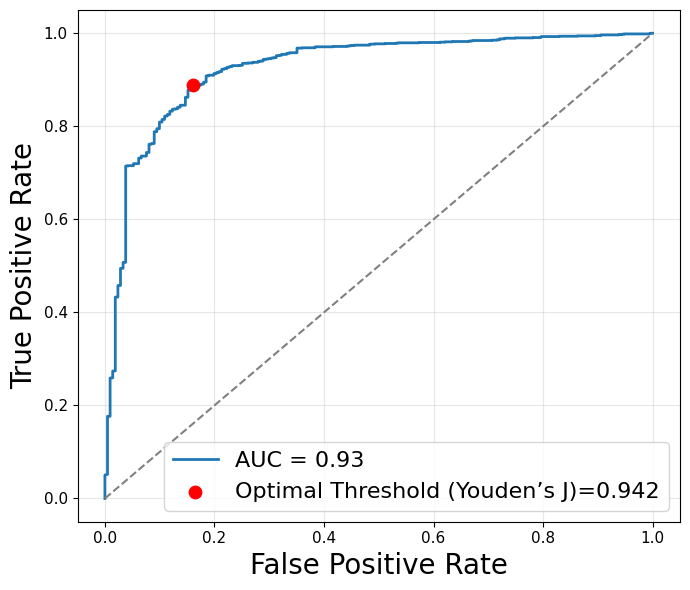

In [14]:
o = pd.read_csv(SD / "fig19" / "4_class_tumor_ViT_ebrains.csv")
y, s = o.InDist.to_numpy(int), o.MaxProb.to_numpy(float)
a = roc_auc_score(y, s)
thr, bf, bt, fpr, tpr, bi = youden(y, s)
ood = s[y == 0]
print(f"in-distribution n = {y.sum()}, OOD n = {(y == 0).sum()} (OOD subclasses: {o.loc[o.InDist == 0, 'Subclass'].value_counts().to_dict()})")
print(f"AUC = {a:.3f}; Youden threshold = {thr:.3f} (TPR {bt:.3f}, FPR {bf:.3f})")
print(f"OOD WSIs below threshold: {(ood < thr).sum()}/{ood.size} = {(ood < thr).mean():.1%}; "
      f"in-distribution WSIs >= threshold: {(s[y == 1] >= thr).sum()}/{y.sum()}")

reset_style()
fig = plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"AUC = {a:.2f}", linewidth=2)
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.scatter(bf, bt, color="red", s=80, label=f"Optimal Threshold (Youden\u2019s J)={thr:.3f}", zorder=5)
plt.xlabel("False Positive Rate", fontsize=20); plt.ylabel("True Positive Rate", fontsize=20)
plt.xticks(fontsize=11); plt.yticks(fontsize=11)
plt.legend(fontsize=16); plt.grid(alpha=0.3); plt.tight_layout()
save(fig, "SF19_OOD_ROC")

## Supplementary Figs 20, 21

TCGA projects: {('Epithelial pattern', 'BRCA'): 220, ('Epithelial pattern', 'LUAD'): 201, ('Epithelial pattern', 'COAD'): 200, ('Glial histology', 'GBM'): 201, ('Glial histology', 'LGG'): 201}
SF20: n = 1023; per class {'Epithelial pattern': 621, 'Glial histology': 402}; accuracy (argmax) = 0.933
   Epithelial pattern         AUC = 0.989
   Glial histology            AUC = 0.991


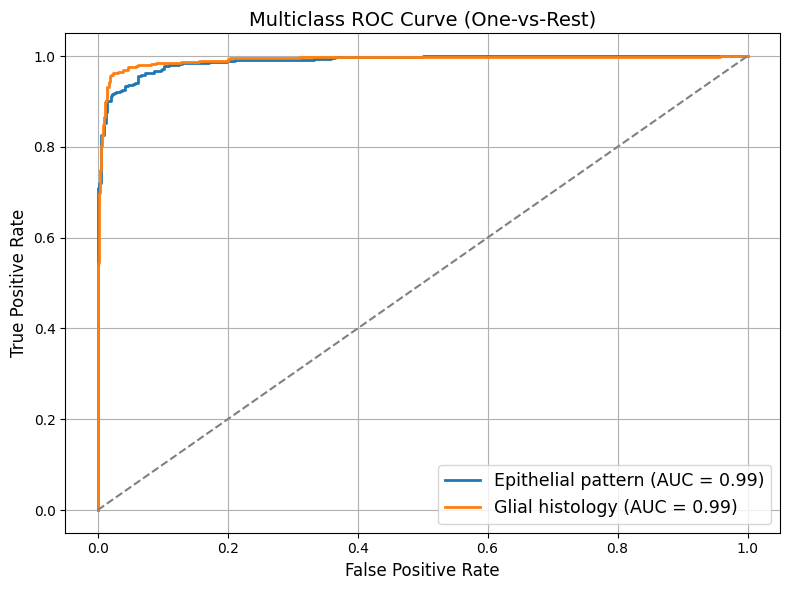

local file rows = 100; InDist == 1: 82
SF21: n = 82; per class {'Epithelial pattern': 20, 'Glial histology': 29, 'Meningothelial Histology': 27, 'Schwannian histology': 6}; accuracy (argmax) = 0.963
   Epithelial pattern         AUC = 0.999
   Glial histology            AUC = 0.999
   Meningothelial Histology   AUC = 1.000
   Schwannian histology       AUC = 1.000


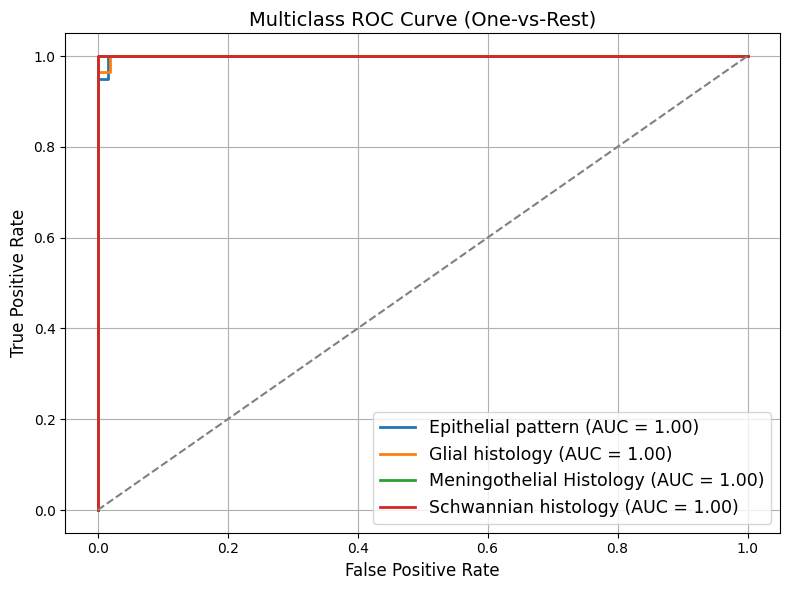

In [15]:
def ovr_panel(df, name, fig_name):
    truth = df["Class"].map({c: i for i, c in enumerate(UMB)}).to_numpy()
    P = df[UMB].to_numpy(float)
    present = [j for j in range(4) if (truth == j).any()]
    point = ovr_aucs(truth, P, present)
    acc = (P.argmax(1) == truth).mean()
    print(f"{name}: n = {len(df)}; per class {dict(zip([UMB[j] for j in present], [int((truth == j).sum()) for j in present]))}; "
          f"accuracy (argmax) = {acc:.3f}")
    for j, a in zip(present, point):
        print(f"   {UMB[j]:26s} AUC = {a:.3f}")
    reset_style()
    fig = plt.figure(figsize=(8, 6))
    for k, j in enumerate(present):
        f_, t_, _ = roc_curve(truth == j, P[:, j])
        plt.plot(f_, t_, lw=2, color=f"C{k}", label=f"{UMB[j]} (AUC = {auc(f_, t_):.2f})")
    plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
    plt.xlabel("False Positive Rate", fontsize=12); plt.ylabel("True Positive Rate", fontsize=12)
    plt.title("Multiclass ROC Curve (One-vs-Rest)", fontsize=14)
    plt.legend(loc="lower right", fontsize=12.5); plt.grid(True); plt.tight_layout()
    save(fig, fig_name)
    return truth

tc = pd.read_csv(SD / "fig20" / "four_class_tumor_ViT_tcga.csv")
print("TCGA projects:", tc.groupby("Class").Subclass.value_counts().to_dict())
_ = ovr_panel(tc, "SF20", "SF20_TCGA_ROC")

lc = pd.read_csv(SD / "fig21" / "four_class_tumor_vit_local.csv")
print(f"local file rows = {len(lc)}; InDist == 1: {(lc.InDist == 1).sum()}")
lc = lc[lc.InDist == 1].copy()
_ = ovr_panel(lc, "SF21", "SF21_local_ROC")

## Supplementary Figs 24, 25

tile rows = 2484; slides = 207; tiles per slide x magnification = [3]
WSIs per class: {'Epithelial': 46, 'Glial': 54, 'Meningothelial': 54, 'Schwannian': 53}
5x: accuracy = 0.348 (72/207); confusion matrix (rows = true):
[[44  1  1  0]
 [36 15  3  0]
 [40  1 13  0]
 [28  1 24  0]]
10x: accuracy = 0.657 (136/207); confusion matrix (rows = true):
[[38  7  1  0]
 [ 3 42  6  3]
 [22  2 30  0]
 [ 7  1 19 26]]
20x: accuracy = 0.899 (186/207); confusion matrix (rows = true):
[[38  8  0  0]
 [ 0 52  2  0]
 [ 2  0 52  0]
 [ 0  5  4 44]]
40x: accuracy = 0.816 (169/207); confusion matrix (rows = true):
[[29 13  4  0]
 [ 0 54  0  0]
 [ 2  3 49  0]
 [ 0 12  4 37]]


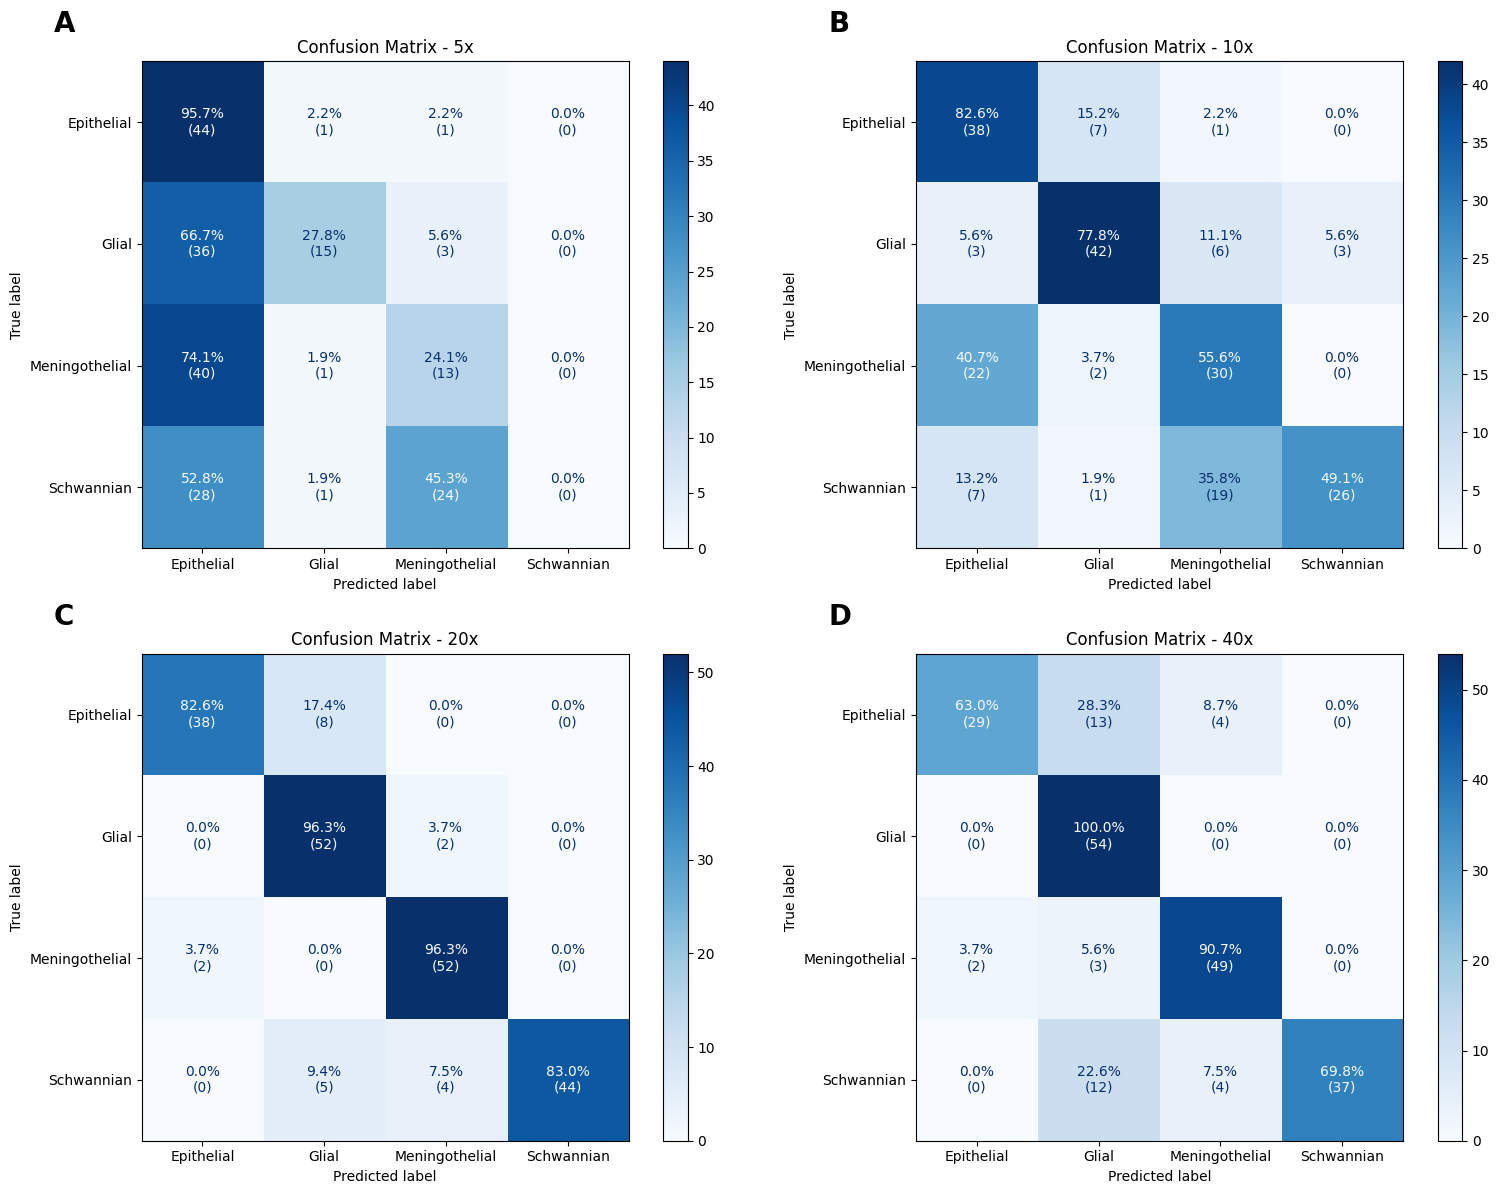

In [16]:
ab = pd.read_csv(SD / "fig24" / "magnification_ablation.csv")
LAB4 = ["Epithelial", "Glial", "Meningothelial", "Schwannian"]
PCOL = ["prob_epithelial", "prob_glial", "prob_meningothelial", "prob_schwannian"]
MAGS = ["5x", "10x", "20x", "40x"]
print(f"tile rows = {len(ab)}; slides = {ab.groupby(['class_folder', 'case_name']).ngroups}; "
      f"tiles per slide x magnification = {sorted(ab.groupby(['class_folder', 'case_name', 'magnification']).size().unique())}")
slide = {}
for mag in MAGS:
    g = ab[ab.magnification == mag].groupby(["class_folder", "case_name"])
    P = g[PCOL].mean(); P = P.div(P.sum(axis=1), axis=0)
    t = g["y_true"].first().loc[P.index].to_numpy()
    slide[mag] = (t, P.to_numpy())
t5 = slide["5x"][0]
print("WSIs per class:", dict(zip(LAB4, np.bincount(t5))))


reset_style()
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for ax, mag, letter in zip(axes.ravel(), MAGS, "ABCD"):
    t, P = slide[mag]; pred = P.argmax(1)
    cmx = confusion_matrix(t, pred, labels=[0, 1, 2, 3])
    acc = accuracy_score(t, pred)
    print(f"{mag}: accuracy = {acc:.3f} ({(t == pred).sum()}/{len(t)}); confusion matrix (rows = true):\n{cmx}")
    disp = ConfusionMatrixDisplay(confusion_matrix=cmx, display_labels=LAB4)
    disp.plot(cmap="Blues", ax=ax, values_format="d")
    for i in range(4):
        for j in range(4):
            disp.text_[i, j].set_text(f"{cmx[i, j] / cmx[i].sum() * 100:.1f}%\n({cmx[i, j]})")
    ax.set_title(f"Confusion Matrix - {mag}")
    ax.text(-0.18, 1.06, letter, transform=ax.transAxes, fontsize=20, fontweight="bold")
plt.tight_layout()
save(fig, "SF24_magnification_confusion_matrices")

,magnification,curve,AUC
0,5x,Epithelial,0.790
1,5x,Glial,0.802
2,5x,Meningothelial,0.553
3,5x,Schwannian,0.689
4,5x,micro-average,0.593
5,5x,macro-average,0.712
6,10x,Epithelial,0.905
7,10x,Glial,0.961
8,10x,Meningothelial,0.791
9,10x,Schwannian,0.928


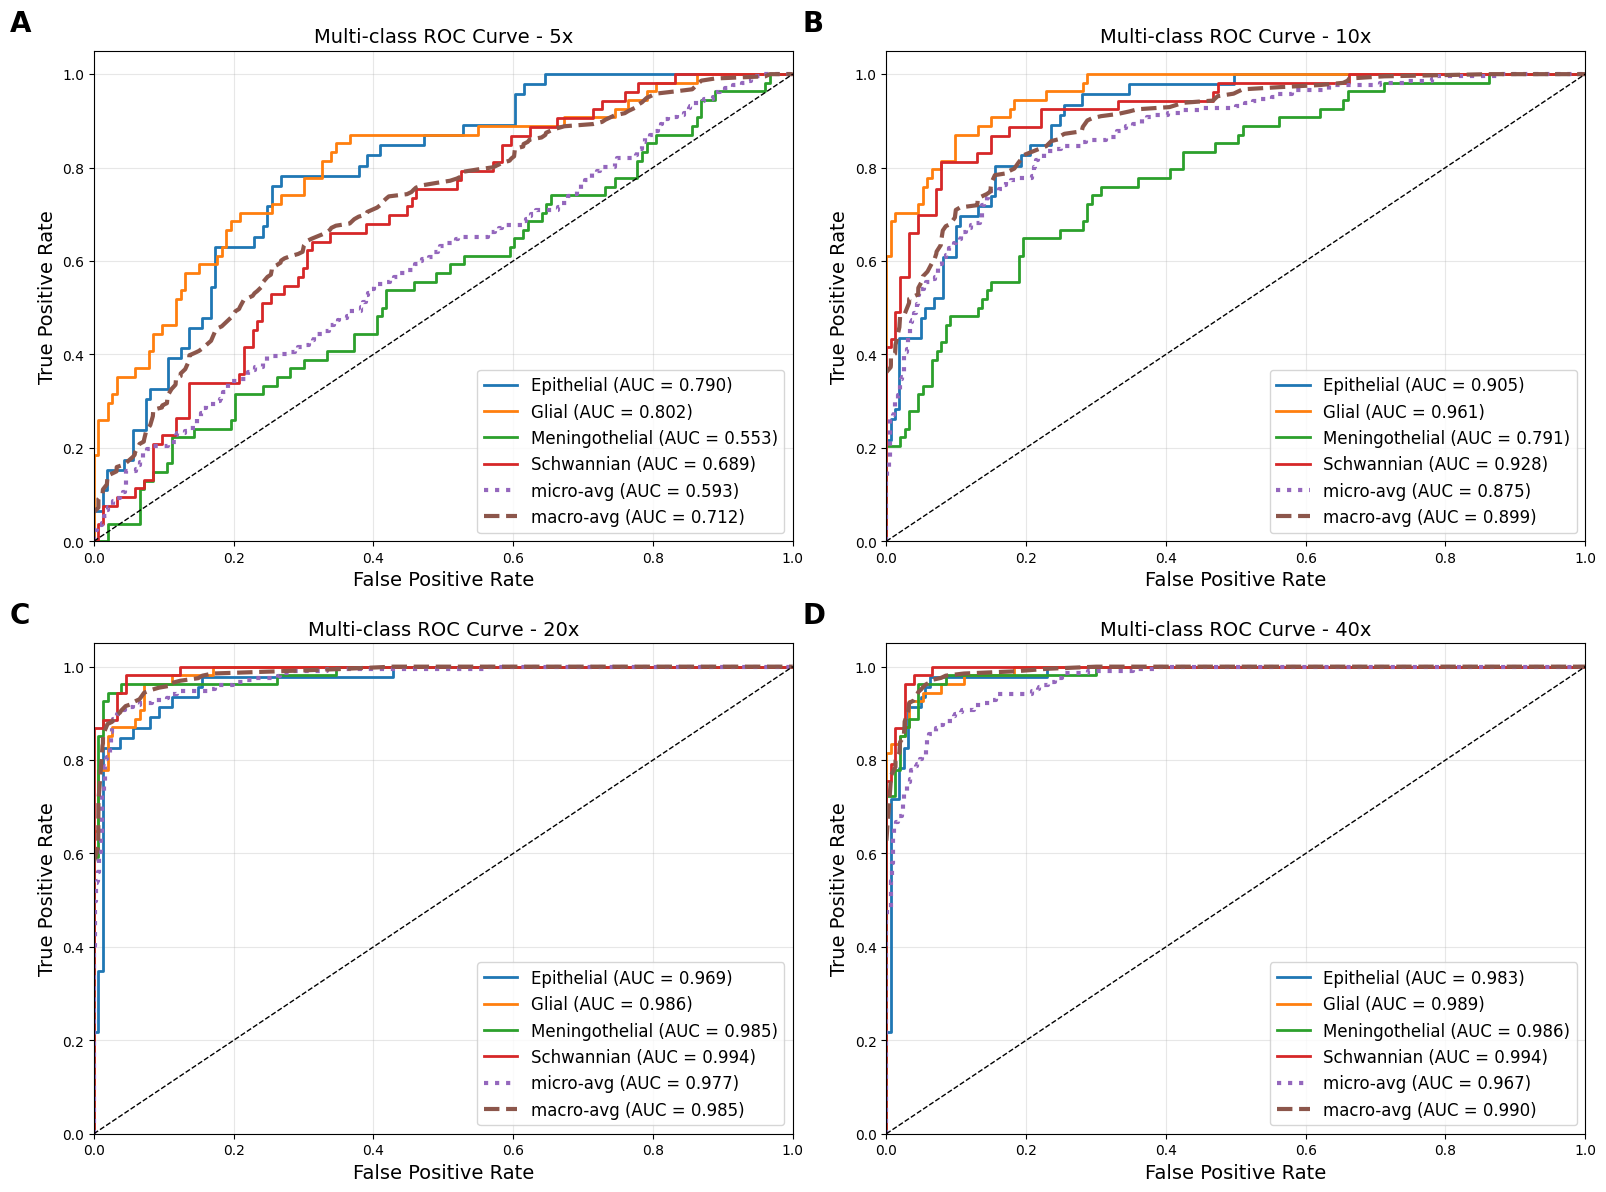

In [17]:
reset_style()
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
rows25 = []
for ax, mag, letter in zip(axes.ravel(), MAGS, "ABCD"):
    t, P = slide[mag]
    Y = label_binarize(t, classes=[0, 1, 2, 3])
    point = ovr_aucs(t, P, [0, 1, 2, 3], macro=True)
    f_mi, t_mi, _ = roc_curve(Y.ravel(), P.ravel()); auc_micro = auc(f_mi, t_mi)
    fpr, tpr = {}, {}
    for i in range(4):
        fpr[i], tpr[i], _ = roc_curve(Y[:, i], P[:, i])
    all_f = np.unique(np.concatenate([fpr[i] for i in range(4)]))
    mean_t = np.mean([np.interp(all_f, fpr[i], tpr[i]) for i in range(4)], axis=0)
    auc_macro = auc(all_f, mean_t)
    for i in range(4):
        rows25.append(dict(magnification=mag, curve=LAB4[i], AUC=point[i]))
    rows25.append(dict(magnification=mag, curve="micro-average", AUC=auc_micro))
    rows25.append(dict(magnification=mag, curve="macro-average", AUC=auc_macro))
    for i in range(4):
        ax.plot(fpr[i], tpr[i], lw=2, label=f"{LAB4[i]} (AUC = {point[i]:.3f})")
    ax.plot(f_mi, t_mi, linestyle=":", linewidth=3, label=f"micro-avg (AUC = {auc_micro:.3f})")
    ax.plot(all_f, mean_t, linestyle="--", linewidth=3, label=f"macro-avg (AUC = {auc_macro:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlim([0.0, 1.0]); ax.set_ylim([0.0, 1.05])
    ax.set_xlabel("False Positive Rate", fontsize=14); ax.set_ylabel("True Positive Rate", fontsize=14)
    ax.set_title(f"Multi-class ROC Curve - {mag}", fontsize=14)
    ax.legend(loc="lower right", fontsize="large"); ax.grid(alpha=0.3)
    ax.text(-0.12, 1.04, letter, transform=ax.transAxes, fontsize=20, fontweight="bold")
display(pd.DataFrame(rows25).style.format({"AUC": "{:.3f}"}))
plt.tight_layout()
save(fig, "SF25_magnification_ROC")

## Supplementary Fig 28

n = 40 pairs ({'10x': 10, '20x': 10, '30x': 10, '40x': 10}); r(38) = 0.9981, p = 7.98e-48, 95% CI [0.996, 0.999]
MAPE by magnification (%): {'10x': 4.03, '20x': 3.93, '30x': 4.28, '40x': 8.41}


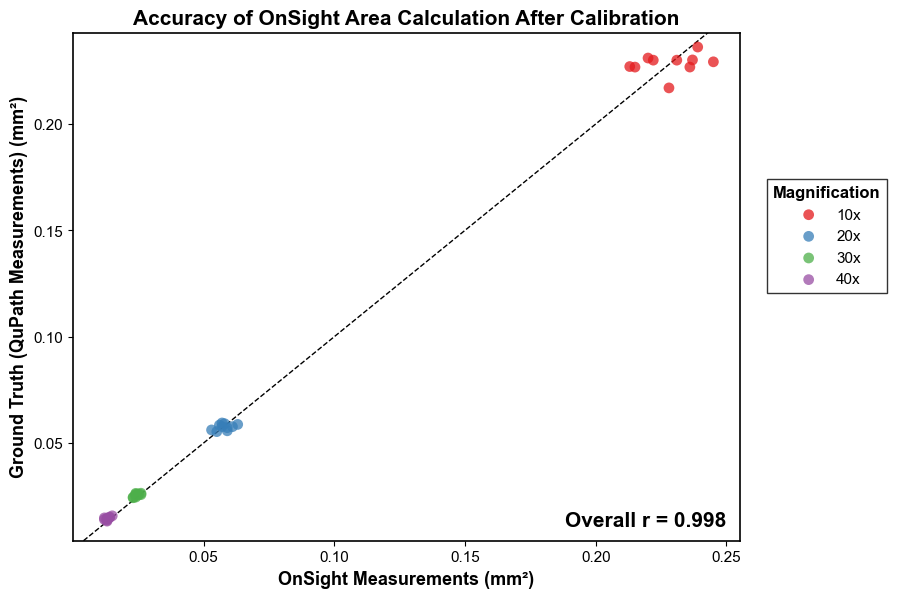

In [18]:
cal = pd.read_csv(SD / "fig28" / "Calibration_validation.csv")
cols = list(cal.columns)
long28 = pd.concat([pd.DataFrame({"magnification": cols[i].split()[-1], "QuPath": cal[cols[i]], "OnSight": cal[cols[i + 1]]})
                    for i in range(0, len(cols), 2)], ignore_index=True)
pf = pearson_fisher(long28.QuPath, long28.OnSight)
print(f"n = {pf['n']} pairs ({long28.magnification.value_counts().sort_index().to_dict()}); "
      f"r({pf['df']}) = {pf['r']:.4f}, p = {pf['p']:.2e}, 95% CI {ci3(pf['ci_low'], pf['ci_high'])}")
mape = long28.assign(ape=(long28.OnSight - long28.QuPath).abs() / long28.QuPath * 100).groupby("magnification", sort=False).ape.mean()
print("MAPE by magnification (%):", mape.round(2).to_dict())

reset_style(**{"font.family": "sans-serif", "font.sans-serif": SANS})
SET1 = {"10x": "#E41A1C", "20x": "#377EB8", "30x": "#4DAF4A", "40x": "#984EA3"}
fig, ax = plt.subplots(figsize=(8.6, 6.6))
for m, g in long28.groupby("magnification", sort=False):
    ax.scatter(g.OnSight, g.QuPath, s=60, color=SET1[m], alpha=0.75, edgecolors="none", label=m, zorder=3)
ax.axline((0, 0), slope=1, linestyle="--", color="black", lw=1)
ax.set_xlim(0.0, 0.255); ax.set_ylim(0.004, 0.243)
ax.xaxis.set_major_locator(MultipleLocator(0.05)); ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.set_xticks([0.05, 0.10, 0.15, 0.20, 0.25]); ax.set_yticks([0.05, 0.10, 0.15, 0.20])
ax.xaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%.2f")); ax.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%.2f"))
ax.set_xlabel("OnSight Measurements (mm\u00b2)", fontsize=13, fontweight="bold")
ax.set_ylabel("Ground Truth (QuPath Measurements) (mm\u00b2)", fontsize=13, fontweight="bold")
ax.set_title("Accuracy of OnSight Area Calculation After Calibration", fontsize=15, fontweight="bold")
ax.text(0.98, 0.02, f"Overall r = {pf['r']:.3f}", transform=ax.transAxes, ha="right", va="bottom", fontsize=15, fontweight="bold")
ax.tick_params(labelsize=11)
for sp in ax.spines.values(): sp.set_linewidth(1.2)
leg = ax.legend(title="Magnification", loc="center left", bbox_to_anchor=(1.03, 0.6), frameon=True, fancybox=False,
                edgecolor="black", fontsize=11, title_fontproperties={"weight": "bold", "size": 12}, markerscale=1.0)
save(fig, "SF28_calibration")

## Supplementary Fig 29

EBRAINS: 4180 patches from 209 WSIs; per-magnification accuracy {'40X': '100.00%', '20X': '98.95%', '10X': '99.90%', '5X': '100.00%'}; overall 99.71%
[[1045    0    0    0]
 [  11 1034    0    0]
 [   0    0 1044    1]
 [   0    0    0 1045]]
Local: 1840 patches from 92 WSIs; per-magnification accuracy {'40X': '100.00%', '20X': '99.57%', '10X': '100.00%', '5X': '100.00%'}; overall 99.89%
[[460   0   0   0]
 [  2 458   0   0]
 [  0   0 460   0]
 [  0   0   0 460]]


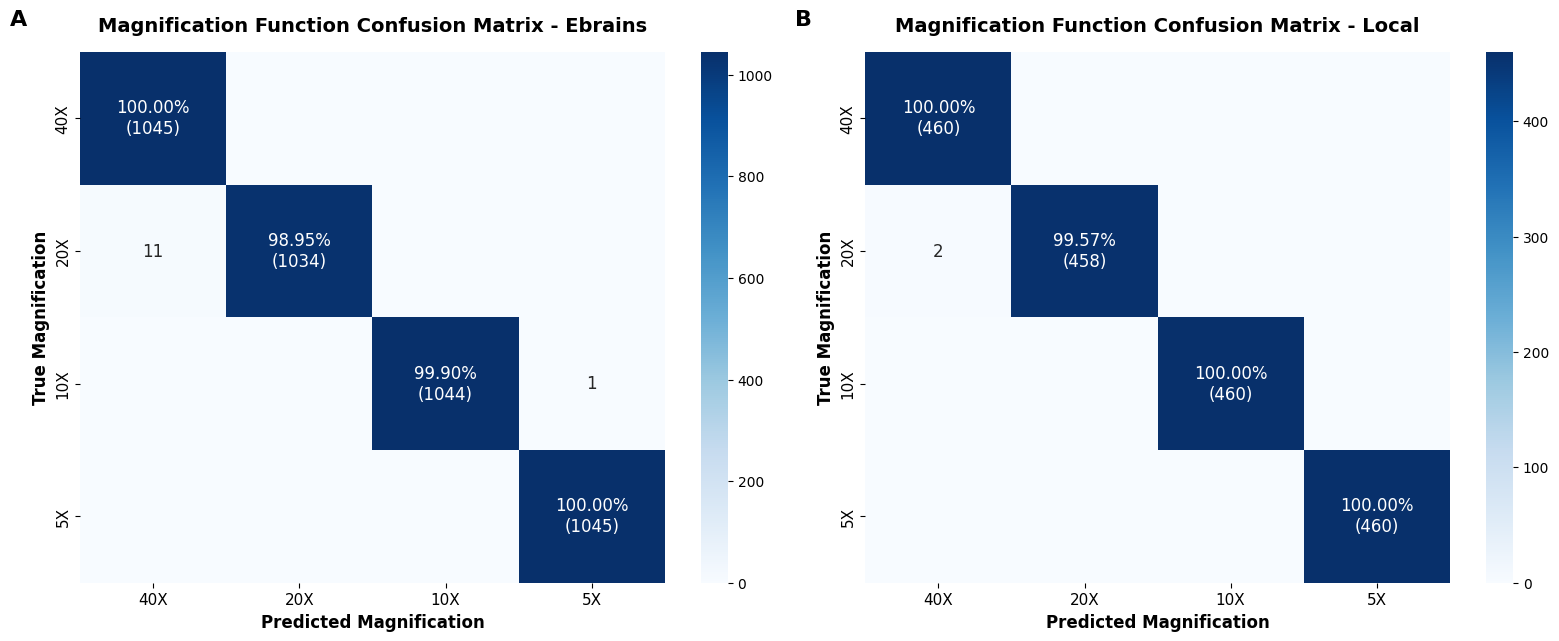

In [19]:
MAG_LABELS = ["40X", "20X", "10X", "5X"]
def process_df(df):
    y_true, y_pred = [], []
    for mag in MAG_LABELS:
        for cell in df[mag].dropna().astype(str):
            preds = [p.strip() for p in cell.split(",") if p.strip()]
            preds = [p + "X" if not p.endswith("X") else p for p in preds]
            y_true.extend([mag] * len(preds)); y_pred.extend(preds)
    return y_true, y_pred

def plot_cm(y_true, y_pred, ax, title):
    cmx = confusion_matrix(y_true, y_pred, labels=MAG_LABELS)
    acc = np.divide(cmx.diagonal(), cmx.sum(axis=1), out=np.zeros(4), where=cmx.sum(axis=1) != 0)
    annot = np.empty_like(cmx).astype(object)
    for i in range(4):
        for j in range(4):
            annot[i, j] = f"{acc[i]:.2%}\n({cmx[i, j]})" if i == j else (f"{cmx[i, j]}" if cmx[i, j] > 0 else "")
    sns.heatmap(cmx, annot=annot, fmt="", cmap="Blues", ax=ax, xticklabels=MAG_LABELS, yticklabels=MAG_LABELS,
                cbar=True, annot_kws={"size": 12})
    ax.set_title(title, fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel("Predicted Magnification", fontsize=12, fontweight="bold")
    ax.set_ylabel("True Magnification", fontsize=12, fontweight="bold")
    ax.tick_params(axis="both", which="major", labelsize=11)
    return cmx, acc

reset_style()
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (name, fn, title, letter) in zip(axes, [("EBRAINS", "A_ebrains.csv", "Magnification Function Confusion Matrix - Ebrains", "A"),
                                                ("Local", "B_local_anonymized.csv", "Magnification Function Confusion Matrix - Local", "B")]):
    d = pd.read_csv(SD / "fig29" / fn)
    yt, yp = process_df(d)
    cmx, acc = plot_cm(yt, yp, ax, title)
    ax.text(-0.12, 1.05, letter, transform=ax.transAxes, fontsize=16, fontweight="bold")
    print(f"{name}: {len(yt)} patches from {len(d)} WSIs; per-magnification accuracy "
          f"{dict(zip(MAG_LABELS, [f'{a:.2%}' for a in acc]))}; overall {np.trace(cmx) / cmx.sum():.2%}\n{cmx}")
plt.tight_layout()
save(fig, "SF29_magnification_detector")

## Supplementary Fig 30

n = 234 candidates (26 mitoses, 208 non-mitoses) from 46 HPF images
AUC = 0.750; Youden threshold = 27.50 (0-100) = 0.275 (0-1)
at threshold (score >= thr): TP 19, FP 53, FN 7, TN 155; sensitivity 0.731, specificity 0.745, F1 = 0.388


,Method,F1-score
0,OnSight,0.388
1,CUHK,0.333
2,YILDIZ,0.172
3,MINES–CURIE–INSERM,0.171
4,STRASBOURG,0.024


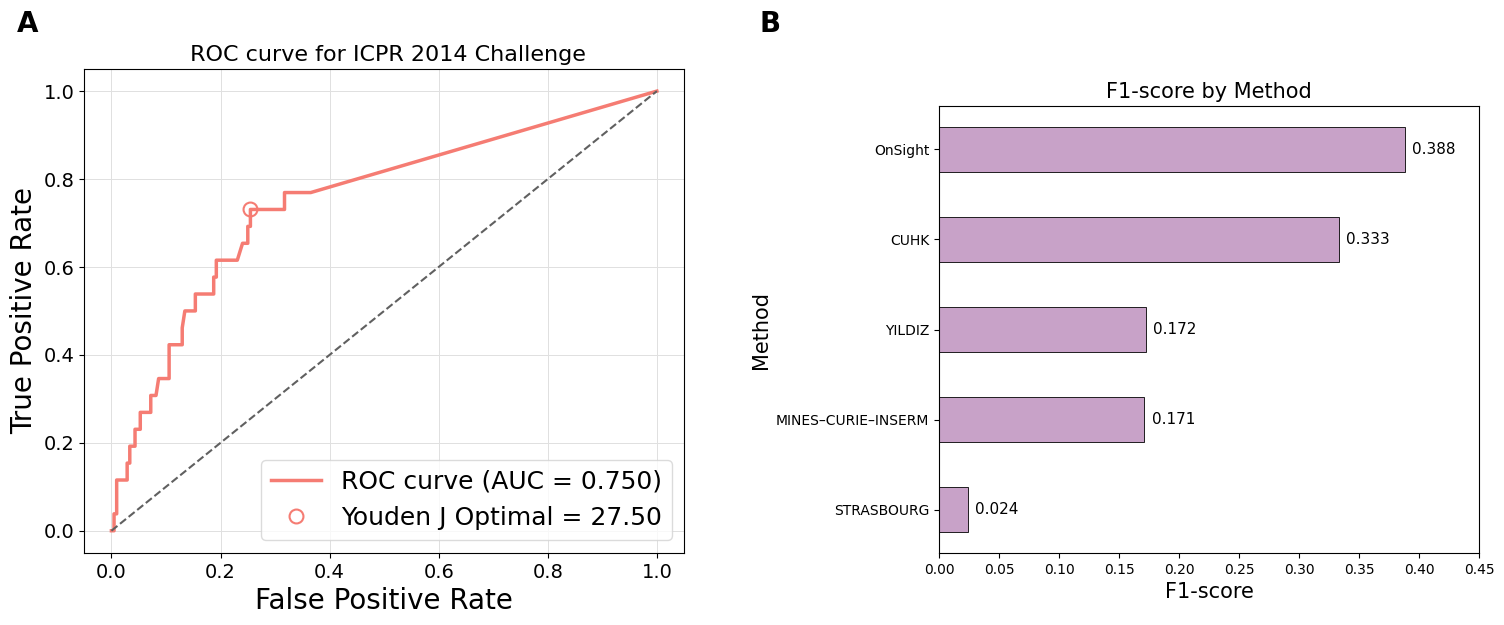

In [20]:
ic = pd.read_csv(SD / "fig30" / "A_ROC.csv", encoding="utf-8-sig")
ic.columns = ic.columns.str.strip()
ic["y_true"] = ic["Yes/No"].str.lower().str.strip().map({"yes": 1, "no": 0})
ic["y_scores"] = pd.to_numeric(ic["Confidence"], errors="coerce")
ic = ic.dropna(subset=["y_true", "y_scores"])
y, s = ic.y_true.to_numpy(int), ic.y_scores.to_numpy(float)
a = roc_auc_score(y, s)
thr, bf, bt, fpr, tpr, bi = youden(y, s)
yp = (s >= thr).astype(int)
f1_on = f1_score(y, yp)
tn, fp, fn, tp = confusion_matrix(y, yp).ravel()
print(f"n = {len(y)} candidates ({y.sum()} mitoses, {(y == 0).sum()} non-mitoses) from {ic['Case ID'].nunique()} HPF images")
print(f"AUC = {a:.3f}; Youden threshold = {thr:.2f} (0-100) = {thr / 100:.3f} (0-1)")
print(f"at threshold (score >= thr): TP {tp}, FP {fp}, FN {fn}, TN {tn}; sensitivity {tp / (tp + fn):.3f}, "
      f"specificity {tn / (tn + fp):.3f}, F1 = {f1_on:.3f}")
f1tab = pd.read_csv(SD / "fig30" / "B_f1_scores.csv", encoding="gbk")
display(f1tab)

reset_style()
PAL = {"red_accent": "#F57C73", "grey": "#606060", "light_grey": "#E0E0E0"}
fig = plt.figure(figsize=(15, 6.2))
axA = fig.add_axes([0.05, 0.12, 0.40, 0.78]); axB = fig.add_axes([0.62, 0.12, 0.36, 0.72])
axA.plot(fpr, tpr, color=PAL["red_accent"], lw=2.5, label=f"ROC curve (AUC = {a:.3f})")
axA.plot(bf, bt, "o", color=PAL["red_accent"], markersize=10, mew=1.5, mfc="none", label=f"Youden J Optimal = {thr:.2f}")
axA.plot([0, 1], [0, 1], color=PAL["grey"], linestyle="--", lw=1.5)
axA.set_title(" ROC curve for ICPR 2014 Challenge", fontsize=16)
axA.set_xlabel("False Positive Rate", fontsize=20); axA.set_ylabel("True Positive Rate", fontsize=20)
axA.legend(loc="lower right", fontsize=18, frameon=True, fancybox=True, edgecolor="lightgray")
axA.grid(True, linewidth=0.7, color=PAL["light_grey"]); axA.tick_params(labelsize=14)
methods_plot, scores_plot = f1tab.Method[::-1].tolist(), f1tab["F1-score"][::-1].tolist()
bars = axB.barh(methods_plot, scores_plot, height=0.5, color="#C8A2C8", edgecolor="black", linewidth=0.6)
axB.set_xlabel("F1-score", fontsize=15); axB.set_ylabel("Method", fontsize=15); axB.set_title("F1-score by Method", fontsize=15)
axB.set_xlim(0, 0.45)
for bar, sc_ in zip(bars, scores_plot):
    axB.text(bar.get_width() + 0.006, bar.get_y() + bar.get_height() / 2, f"{sc_:.3f}", va="center", fontsize=11)
fig.text(0.005, 0.96, "A", fontsize=20, fontweight="bold"); fig.text(0.50, 0.96, "B", fontsize=20, fontweight="bold")
save(fig, "SF30_ICPR2014")

## Supplementary Fig 32

In [21]:
A32 = pd.read_csv(SD / "fig32" / "A_cell_features_vs_distance.csv")
B32 = pd.read_csv(SD / "fig32" / "B_dense_boxplot_cell_features.csv")
LABEL_MIC, LABEL_WSI = "Microscope", "WSI patch"
A_METRICS = [("Size.Area_median", "Median nuclei area", "\u03bcm\u00b2"),
             ("Size.Perimeter_median", "Median nuclei perimeter", "\u03bcm"),
             ("Size.MajorAxisLength_median", "Median nuclei major axis", "\u03bcm"),
             ("Size.MinorAxisLength_median", "Median nuclei minor axis", "\u03bcm")]
r32 = {}
for key, name, unit in A_METRICS:
    mic = A32[A32.dataset == LABEL_MIC][["image", key]].rename(columns={key: "mic"})
    wsi = A32[A32.dataset == LABEL_WSI][["image", key]].rename(columns={key: "wsi"})
    mg = mic.merge(wsi, on="image")
    pf = pearson_fisher(mg.mic, mg.wsi); r32[key] = pf["r"]
    print(f"{name:26s} n = {pf['n']}, r({pf['df']}) = {pf['r']:.3f}, 95% CI {ci3(pf['ci_low'], pf['ci_high'])}, p = {pf['p']:.2e}")
cnt = B32.groupby(["category", "method"]).stem.nunique().unstack()
print("B: patches per density stratum and modality\n", cnt)

Median nuclei area         n = 40, r(38) = 0.884, 95% CI [0.790, 0.937], p = 4.08e-14
Median nuclei perimeter    n = 40, r(38) = 0.886, 95% CI [0.794, 0.939], p = 2.90e-14
Median nuclei major axis   n = 40, r(38) = 0.860, 95% CI [0.750, 0.924], p = 1.14e-12
Median nuclei minor axis   n = 40, r(38) = 0.883, 95% CI [0.789, 0.937], p = 4.44e-14
B: patches per density stratum and modality
 method        Microscope  WSI patch
category                           
Dense_high            12         12
Dense_low             12         12
Dense_medium          12         12


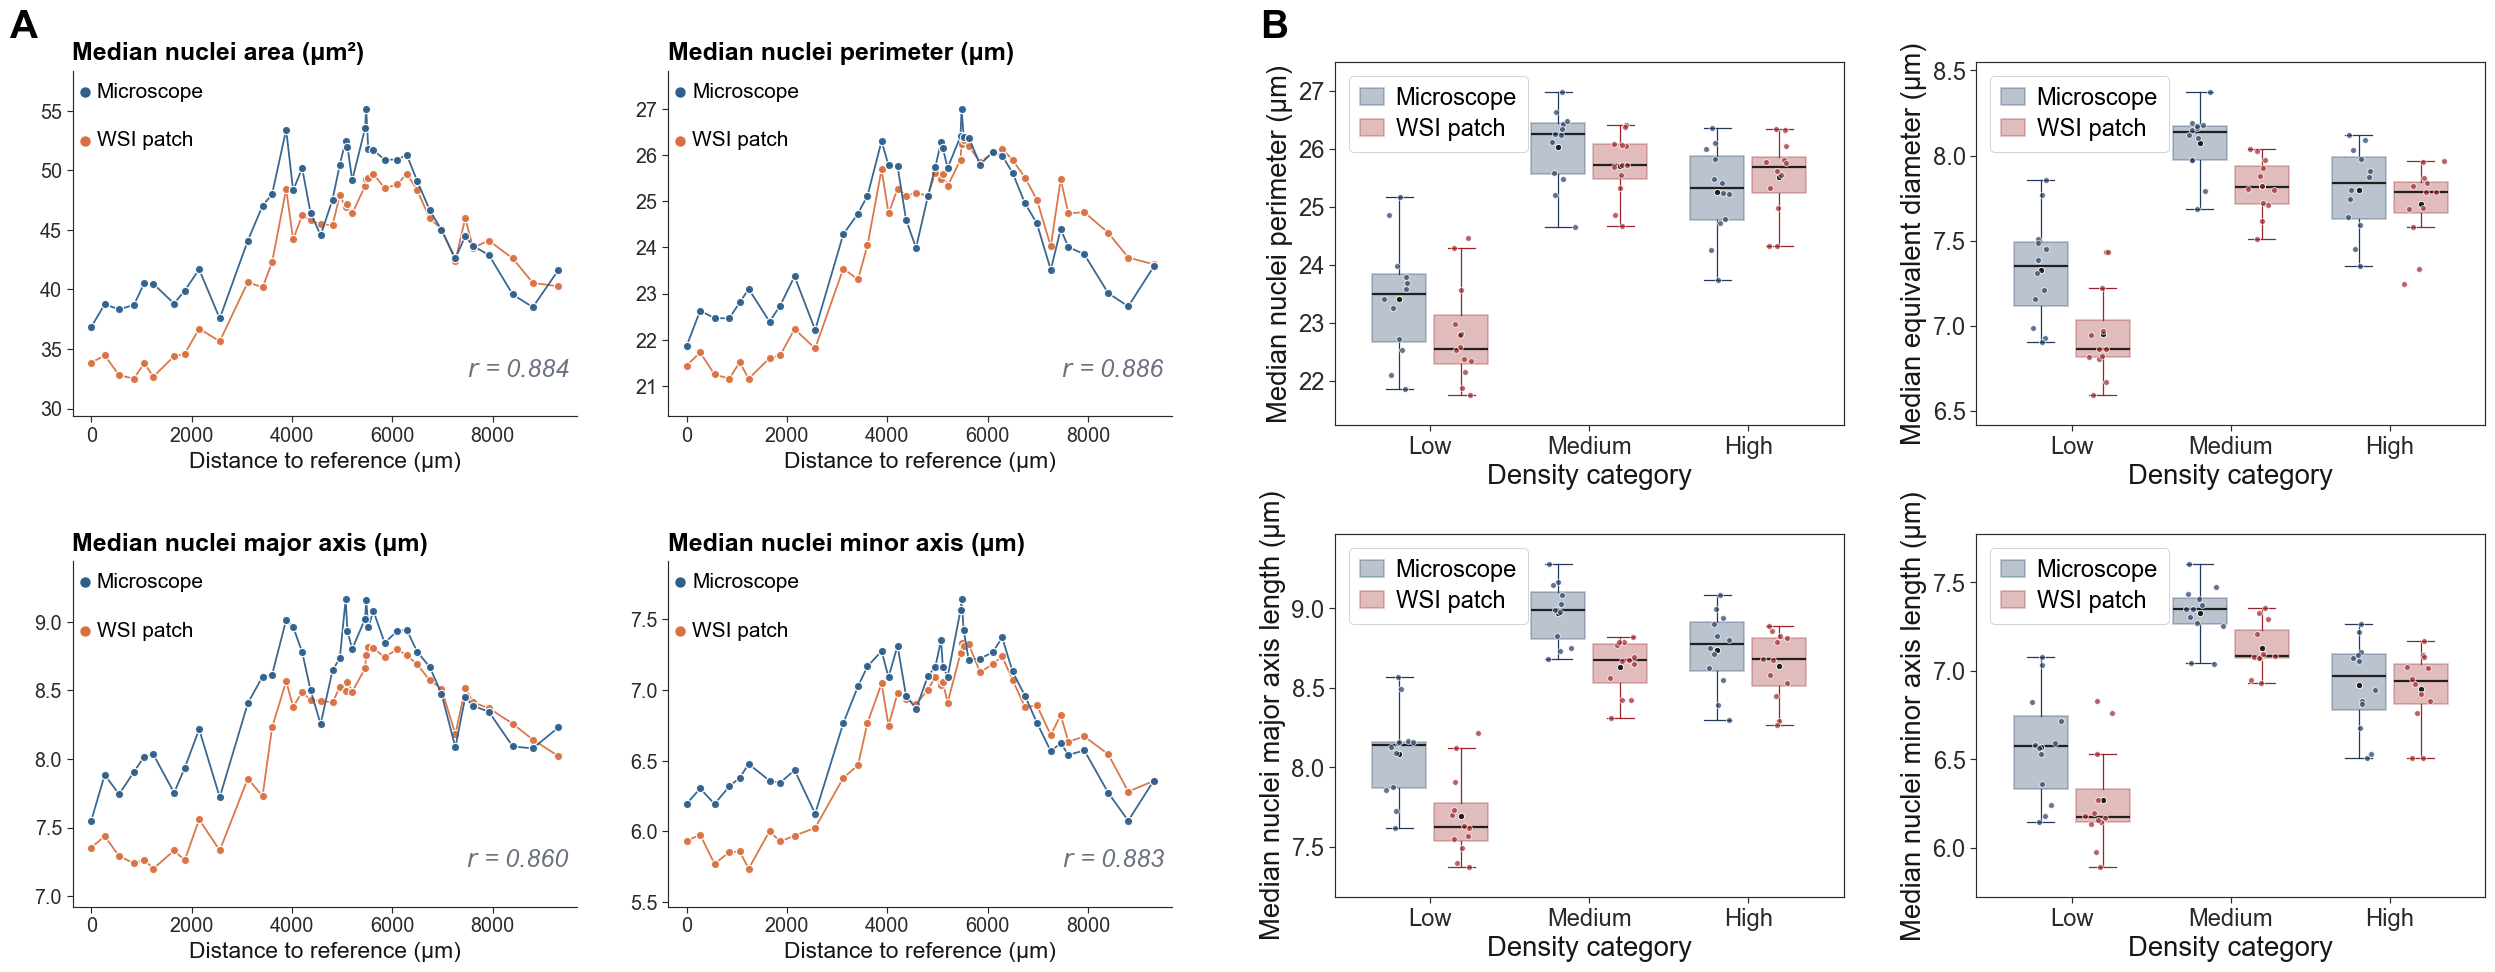

In [22]:
reset_style(**{"font.family": "sans-serif", "font.sans-serif": SANS, "axes.linewidth": 0.85, "xtick.major.width": 0.85,
               "ytick.major.width": 0.85, "xtick.major.size": 4, "ytick.major.size": 4, "axes.edgecolor": "#2A2A2A",
               "xtick.color": "#2A2A2A", "ytick.color": "#2A2A2A", "axes.labelcolor": "#171717"})
fig = plt.figure(figsize=(25, 9.6))
gsA = fig.add_gridspec(2, 2, left=0.03, right=0.47, top=0.94, bottom=0.07, wspace=0.18, hspace=0.42)
gsB = fig.add_gridspec(2, 2, left=0.535, right=0.995, top=0.95, bottom=0.08, wspace=0.26, hspace=0.30)

FSA = 1.5
COLOR_MIC, COLOR_WSI = "#2D5F8C", "#D97041"
for k, (key, name, unit) in enumerate(A_METRICS):
    ax = fig.add_subplot(gsA[k // 2, k % 2])
    for sname in ("top", "right"): ax.spines[sname].set_visible(False)
    for ds, color in [(LABEL_WSI, COLOR_WSI), (LABEL_MIC, COLOR_MIC)]:
        sub = A32[A32.dataset == ds].dropna(subset=["distance_um", key]).sort_values("distance_um")
        ax.errorbar(sub.distance_um, sub[key], fmt="-", color=color, linewidth=1.3, alpha=0.95, marker="o",
                    markersize=6, markerfacecolor=color, markeredgecolor="white", markeredgewidth=0.9, zorder=3)
    ax.set_title(f"{name} ({unit})", loc="left", fontsize=12 * FSA, fontweight="semibold", pad=8)
    ax.set_xlabel("Distance to reference (\u03bcm)", fontsize=11 * FSA)
    ax.tick_params(labelsize=9.5 * FSA)
    ax.margins(x=0.04, y=0.14)
    for i, (color, label) in enumerate([(COLOR_MIC, LABEL_MIC), (COLOR_WSI, LABEL_WSI)]):
        ax.scatter([0.024], [0.95 - i * 0.14 - 0.011], s=42, color=color, transform=ax.transAxes, clip_on=False, zorder=10)
        ax.text(0.048, 0.95 - i * 0.14 - 0.011, label, transform=ax.transAxes, ha="left", va="center", fontsize=10 * FSA)
    ax.text(0.985, 0.10, f"$r$ = {r32[key]:.3f}", transform=ax.transAxes, ha="right", va="bottom",
            fontsize=12 * FSA, color="#6B7280", fontstyle="italic")
fig.text(0.005, 0.975, "A", fontsize=28, fontweight="bold")

FSB = 1.8
CAT = ["Dense_low", "Dense_medium", "Dense_high"]; CAT_LAB = ["Low", "Medium", "High"]
CB_MIC, CB_WSI = "#1E3A5F", "#9B2226"
B_METRICS = [("Size.Perimeter_median", "Median nuclei perimeter", "\u03bcm"),
             ("Shape.EquivalentDiameter_median", "Median equivalent diameter", "\u03bcm"),
             ("Size.MajorAxisLength_median", "Median nuclei major axis length", "\u03bcm"),
             ("Size.MinorAxisLength_median", "Median nuclei minor axis length", "\u03bcm")]
BOX_W, BOX_GAP = 0.34, 0.05
base = np.arange(1, 4); off = (BOX_W + BOX_GAP) / 2
rng = np.random.default_rng(42)
for k, (key, label, unit) in enumerate(B_METRICS):
    ax = fig.add_subplot(gsB[k // 2, k % 2])
    for method, color, pos in [(LABEL_MIC, CB_MIC, base - off), (LABEL_WSI, CB_WSI, base + off)]:
        vals = [B32[(B32.metric_key == key) & (B32.category == c) & (B32.method == method)].value.to_numpy(float) for c in CAT]
        bp = ax.boxplot(vals, positions=pos, widths=BOX_W, patch_artist=True, showfliers=False, showmeans=True,
                        whiskerprops=dict(linewidth=0.9, color=color), capprops=dict(linewidth=0.9, color=color),
                        medianprops=dict(linewidth=1.6, color="#1f1f1f"),
                        meanprops=dict(marker="o", markerfacecolor="#1f1f1f", markeredgecolor="white", markersize=4.5, markeredgewidth=0.6))
        for patch in bp["boxes"]:
            patch.set_facecolor(color); patch.set_alpha(0.30); patch.set_edgecolor(color); patch.set_linewidth(1.2)
    for i, c in enumerate(CAT):
        for method, color, p in [(LABEL_MIC, CB_MIC, base[i] - off), (LABEL_WSI, CB_WSI, base[i] + off)]:
            v = B32[(B32.metric_key == key) & (B32.category == c) & (B32.method == method)].value.to_numpy(float)
            ax.scatter(rng.normal(p, 0.05, v.size), v, s=18, c=color, edgecolor="white", linewidth=0.7, alpha=0.7, zorder=4)
    ax.set_xticks(base); ax.set_xticklabels(CAT_LAB); ax.set_xlim(0.4, 3.6)
    ax.set_xlabel("Density category", fontsize=11 * FSB); ax.set_ylabel(f"{label} ({unit})", fontsize=11 * FSB)
    ax.tick_params(labelsize=9.5 * FSB); ax.margins(y=0.10)
    handles = [mpatches.Patch(facecolor=CB_MIC, alpha=0.30, edgecolor=CB_MIC, linewidth=1.2, label=LABEL_MIC),
               mpatches.Patch(facecolor=CB_WSI, alpha=0.30, edgecolor=CB_WSI, linewidth=1.2, label=LABEL_WSI)]
    leg = ax.legend(handles=handles, loc="upper left", fontsize=9.5 * FSB, handlelength=1.0, handletextpad=0.5,
                    borderpad=0.45, borderaxespad=0.6, labelspacing=0.35, frameon=True)
    leg.get_frame().set_linewidth(0.6); leg.get_frame().set_edgecolor("#BCC0C5")
fig.text(0.505, 0.975, "B", fontsize=28, fontweight="bold")
save(fig, "SF32_microscope_vs_WSI")

## Supplementary Fig 33

n responses: 18 {'Cortex': 7, 'Glioma': 6, 'Lymphoma': 5}


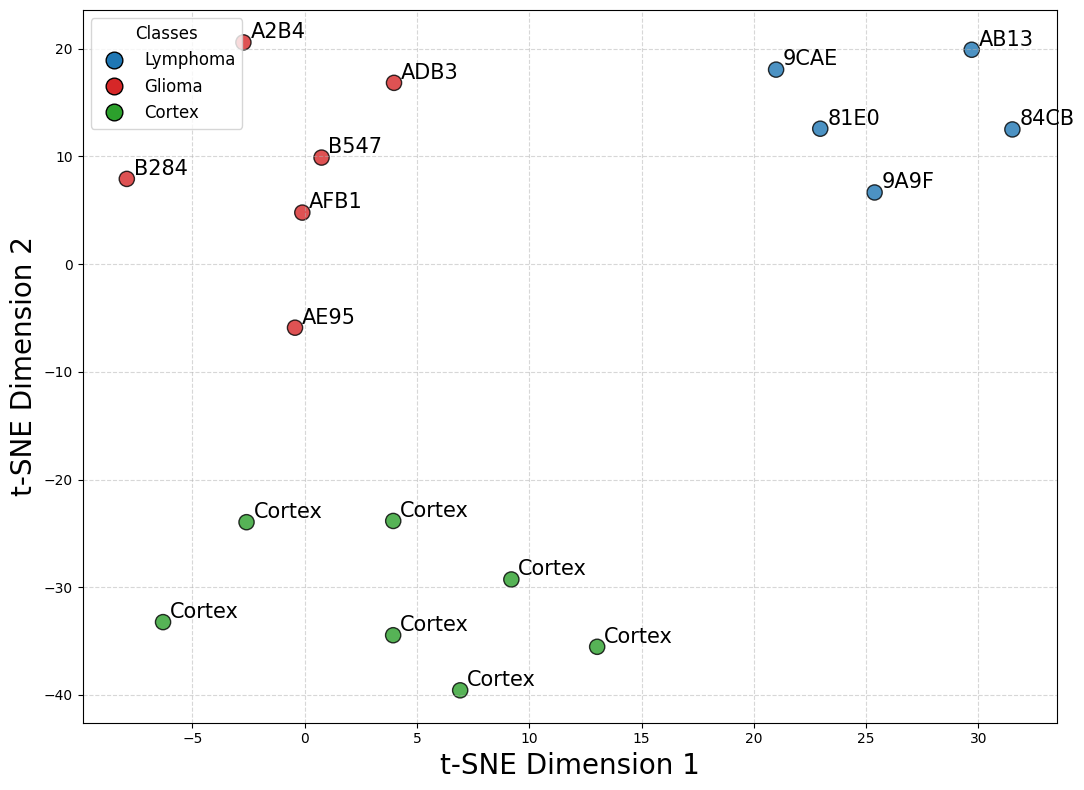

mean within-class cosine similarity: {'Lymphoma': 0.784, 'Glioma': 0.655, 'Cortex': 0.838} | mean between-class: 0.532
leaf order (top to bottom): ['Cortex (local)', 'Cortex (local)', 'Cortex (local)', 'Cortex (local)', 'Cortex (local)', 'Cortex (local)', 'Cortex (local)', 'Lymphoma 9A9F', 'Lymphoma 81E0', 'Lymphoma 9CAE', 'Lymphoma 84CB', 'Lymphoma AB13', 'Glioma AE95', 'Glioma B547', 'Glioma AFB1', 'Glioma B284', 'Glioma A2B4', 'Glioma ADB3']


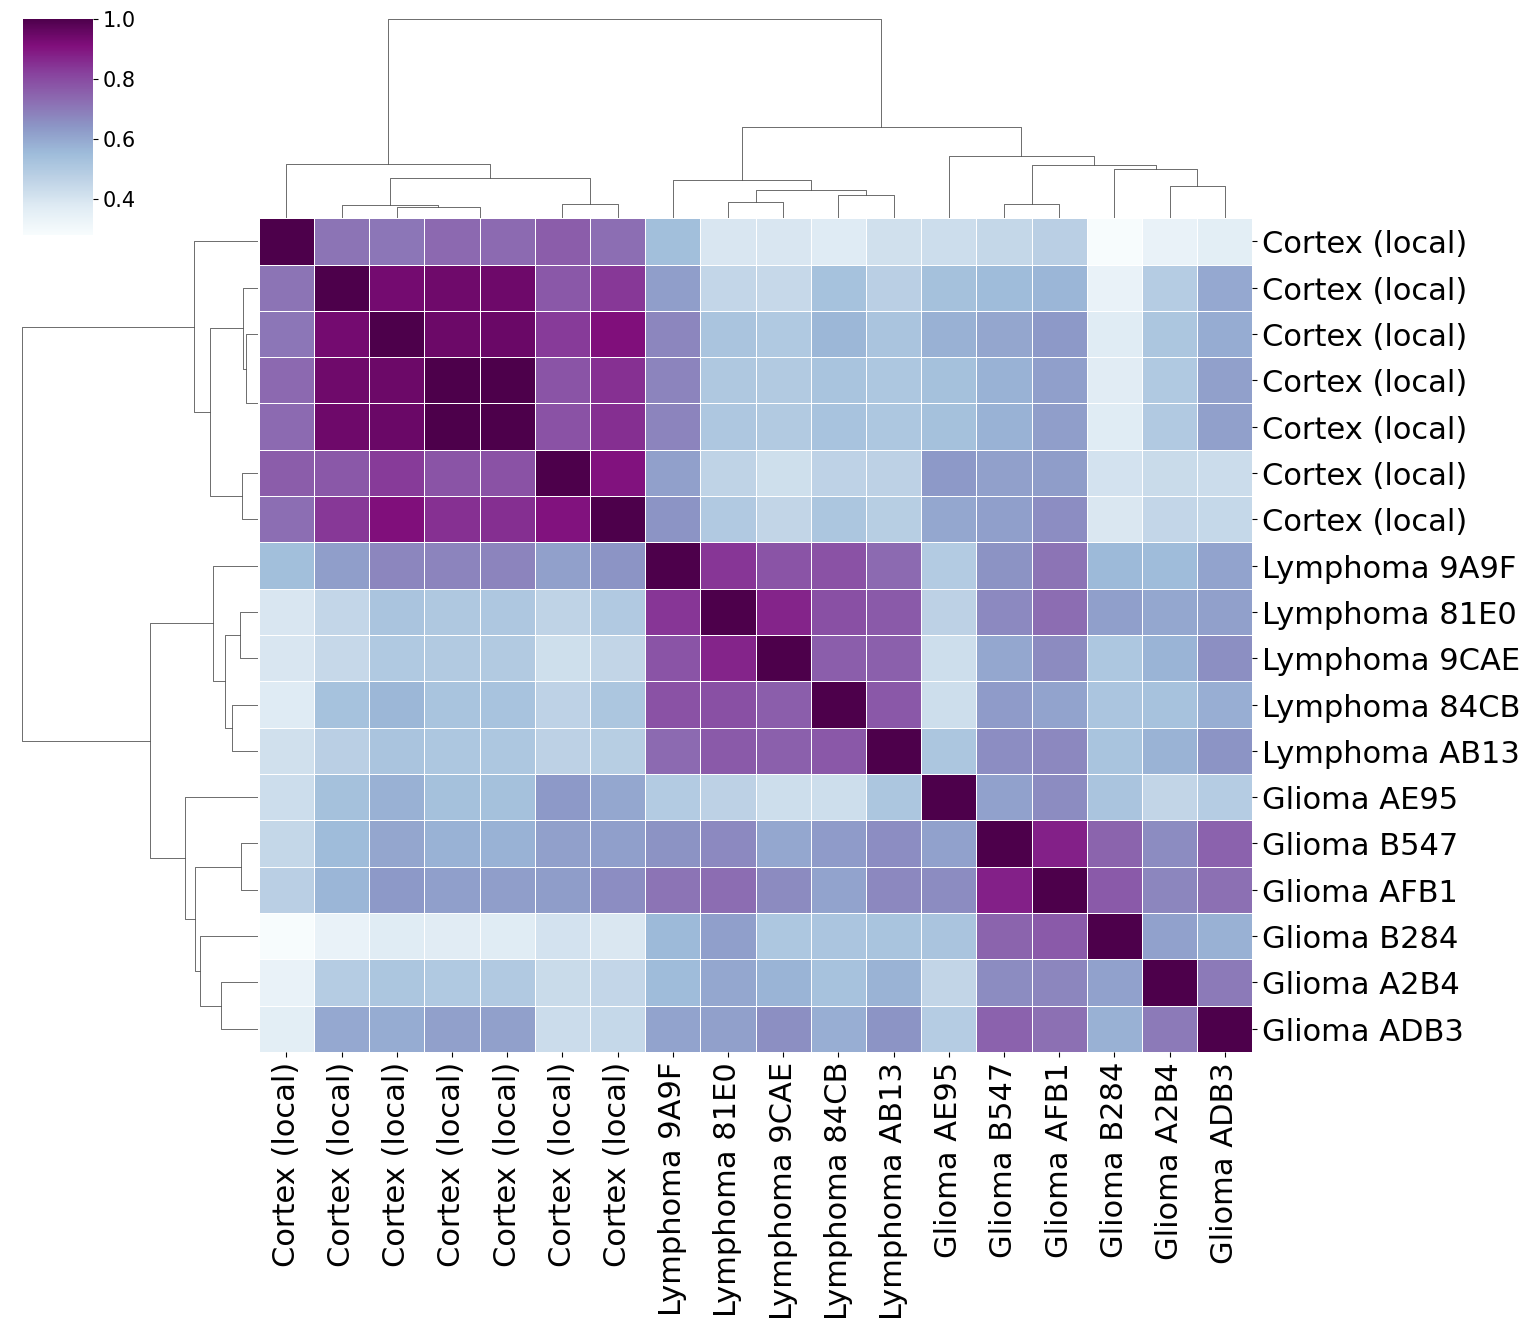

In [23]:
ts = pd.read_excel(SD / "fig33" / "Supp_Fig_33h_tSNE.xlsx")
print("n responses:", len(ts), ts.Class.value_counts().to_dict())
reset_style()
color_map = {"Lymphoma": "#1f77b4", "Glioma": "#d62728", "Cortex": "#2ca02c"}
fig = plt.figure(figsize=(11, 8))
plt.scatter(ts.tSNE_1, ts.tSNE_2, c=[color_map[c] for c in ts.Class], s=120, edgecolor="k", alpha=0.8)
for _, r in ts.iterrows():
    lab = "Cortex" if r.Class == "Cortex" else str(r.ID).split()[-1]
    plt.annotate(lab, (r.tSNE_1, r.tSNE_2), textcoords="offset points", xytext=(5, 3), fontsize=15, ha="left")
plt.xlabel("t-SNE Dimension 1", fontsize=20); plt.ylabel("t-SNE Dimension 2", fontsize=20)
handles = [plt.Line2D([0], [0], marker="o", color="w", label=c, markerfacecolor=col, markersize=12, markeredgecolor="k")
           for c, col in color_map.items()]
plt.legend(handles=handles, title="Classes", fontsize=12, title_fontsize=12, loc="best")
plt.grid(True, linestyle="--", alpha=0.5); plt.tight_layout()
save(fig, "SF33h_tSNE")

sim = pd.read_excel(SD / "fig33" / "Supp_Fig_33i_cosine_similarity.xlsx").set_index("ID")
sim.columns = sim.index
sim.index.name = None; sim.columns.name = None
within = {c: sim.values[np.ix_(ts.Class.values == c, ts.Class.values == c)][np.triu_indices((ts.Class == c).sum(), 1)].mean() for c in color_map}
print("mean within-class cosine similarity:", {k: round(v, 3) for k, v in within.items()},
      "| mean between-class:", round(sim.values[ts.Class.values[:, None] != ts.Class.values[None, :]].mean(), 3))
reset_style()
g = sns.clustermap(sim, method="ward", cmap="BuPu", linewidths=.5, figsize=(14, 12), xticklabels=True, yticklabels=True)
g.cax.tick_params(labelsize=15)
g.ax_heatmap.tick_params(axis="x", labelsize=22); g.ax_heatmap.tick_params(axis="y", labelsize=22)
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90); plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0)
order = [sim.index[i] for i in g.dendrogram_row.reordered_ind]
print("leaf order (top to bottom):", order)
g.savefig(OUT / "SF33i_clustermap.png", dpi=300, bbox_inches="tight", facecolor="white")
g.savefig(OUT / "SF33i_clustermap.pdf", bbox_inches="tight", facecolor="white")
plt.show()

## Supplementary Table 3

In [24]:
cols32 = pd.read_csv(SD / "fig32" / "A_cell_features_vs_distance.csv", nrows=0).columns
feats_t3 = sorted({re.sub(r"_(mean|std|median)$", "", c) for c in cols32 if re.match(r"^(Size|Shape|Nucleus)\.", c)})
cat = lambda f: "Nuclear Size" if f.startswith("Size.") or f == "Shape.EquivalentDiameter" else (
    "Nuclear Shape" if f.startswith("Shape.") else "Nuclear Intensity")
t3 = pd.DataFrame({"Category": [cat(f) for f in feats_t3], "Feature": feats_t3}).sort_values(["Category", "Feature"],
      key=lambda s: s.map({"Nuclear Size": 0, "Nuclear Shape": 1, "Nuclear Intensity": 2}) if s.name == "Category" else s)
display(t3.reset_index(drop=True))

,Category,Feature
0,Nuclear Size,Shape.EquivalentDiameter
1,Nuclear Size,Size.Area
2,Nuclear Size,Size.MajorAxisLength
3,Nuclear Size,Size.MinorAxisLength
4,Nuclear Size,Size.Perimeter
5,Nuclear Shape,Shape.Circularity
6,Nuclear Shape,Shape.Eccentricity
7,Nuclear Shape,Shape.Extent
8,Nuclear Shape,Shape.Solidity
9,Nuclear Intensity,Nucleus.Intensity.HistEnergy
